# 📨 9장 · 스팸일까, 아닐까: 분류 (v4 실습 노트북)

『빅데이터분석 with 파이썬』 9장의 실습을 그대로 따라 하는 노트북입니다. **실습 번호는 책 v9판과 같습니다.**

| 표시 | 뜻 | 실습 |
|---|---|---|
| 예제 짝 | 04절 손 계산 예제의 코드판 | 실습 예제 9-1, 9-2 |
| 작은 예제 | 알고리즘을 몇 통으로 한 걸음씩 | 실습 예제 9-4(로지스틱 회귀), 9-7(나이브 베이즈) |
| ★ 필수 | 수업 시간에 모두 함께 | 실습 예제 9-3, 9-5, 9-6, 9-8~9-11 |
| ☆ 코랩 실습 | **이 노트북에만 있는 선택 실습**(책에는 할 일과 결과만) | 코랩 실습 9-1, 9-2, 9-3 |

**데이터**
- 스팸 문자: UCI "SMS Spam Collection" 5,574통(중복을 지우면 5,171통). GitHub 저장소 `justmarkham/pycon-2016-tutorial`에서 바로 읽습니다.
- 미니 프로젝트: 서울 초미세먼지(에어코리아)와 서울 날씨(기상청 ASOS) 두 CSV. 코랩 왼쪽 파일 창에 올립니다.

위에서부터 차례로 실행하세요. 뒤의 실습은 앞 실습에서 만든 변수(`sms`, `train`, `test` 등)를 씁니다.

## 0 · 준비

그래프의 한글이 네모(□)로 깨지지 않게 **koreanize-matplotlib**를 설치합니다.

In [ ]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

**데이터 받기** (깃허브 저장소판에서 덧붙인 셀) — 아래 셀은 미니 프로젝트가 쓰는 강의 자료 파일을 저장소의 `data` 폴더에서 코랩으로 내려받습니다.

In [ ]:
# 이 장의 강의 자료 파일을 책 깃허브 저장소에서 받아 옵니다.
# (파일을 코랩 왼쪽 📁 파일 창에 직접 끌어다 올렸다면 이 셀은 건너뛰어도 됩니다.)
import os, urllib.parse, urllib.request
BASE = "https://raw.githubusercontent.com/yeonu69/bigdata-python-book/main/ch09/data/"
for f in [
    "asos_서울108_시간자료_2023_2026.csv",
    "에어코리아_서울_도시대기평균_시간별_2023_2026.csv",
]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
    print("준비됨:", f, f"({os.path.getsize(f) / 1e6:.1f} MB)")

## 04. 숨어있는 기초 수학: 예제를 코드로

### [실습 예제 9-1] [예제 9-1]을 파이썬 코드로 구현하기

[예제 9-1]의 네 칸 숫자로 정답 열과 판정 열을 만들어, 사이킷런의 점수 함수가 손 계산과 같은 값을 내는지 확인해 봅시다.

**❶ 네 칸의 숫자로 정답과 판정 만들기**

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

TP, FP, FN, TN = 233, 81, 109, 468      # [예제 9-1]의 네 칸
y_true = np.array([1] * TP + [0] * FP + [1] * FN + [0] * TN)   # 실제(산 사람 1)
y_pred = np.array([1] * TP + [1] * FP + [0] * FN + [0] * TN)  # 판정(산다고 함 1)
print("승객:", len(y_true), " 산 사람:", y_true.sum(), " 산다고 함:", y_pred.sum())

승객: 891  산 사람: 342  산다고 함: 314


`[1] * 233`은 1을 233개 늘어놓은 리스트입니다. 네 칸을 차례로 이어 붙이면 891명의 정답과 판정이 같은 순서로 놓입니다. 실제로 산 사람은 TP + FN = 342명, 산다고 판정한 사람은 TP + FP = 314명입니다. `y_true.sum( )`은 1의 개수를 셉니다.

**❷ 혼동행렬을 다시 세어 보기**

In [ ]:
print(confusion_matrix(y_true, y_pred))     # [[TN FP] [FN TP]] 순서

[[468  81]
 [109 233]]


사이킷런의 혼동행렬은 줄이 실제, 칸이 판정이고, 0(음성)이 먼저 옵니다. 그래서 왼쪽 위가 TN, 오른쪽 아래가 TP입니다. [그림 @example_titanic]과 줄 순서가 거꾸로이니 읽을 때 주의합니다.

**❸ 네 점수를 함수로 구하고 손 계산과 견주기**

In [ ]:
hand = {"정확도": 701 / 891, "정밀도": 233 / 314, "재현율": 233 / 342}
hand["F1"] = 2 * hand["정밀도"] * hand["재현율"] / (hand["정밀도"] + hand["재현율"])
func = {"정확도": accuracy_score(y_true, y_pred), "정밀도": precision_score(y_true, y_pred),
        "재현율": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred)}
for k in hand:
    print(f"{k}: 손 계산 {hand[k]:.3f}  함수 {func[k]:.3f}")

정확도: 손 계산 0.787  함수 0.787
정밀도: 손 계산 0.742  함수 0.742
재현율: 손 계산 0.681  함수 0.681
F1: 손 계산 0.710  함수 0.710


네 점수가 모두 같습니다. 함수는 이름만 다를 뿐 (식 9-3), (식 9-4)를 그대로 계산합니다. 숫자가 맞는지 손으로 한 번 확인해 두면, 큰 데이터에서 함수가 낸 점수도 믿고 읽을 수 있습니다.

### [실습 예제 9-2] [예제 9-2]를 파이썬 코드로 구현하기

계산표를 함수 하나로 만들고, 단어를 볼 때마다 사후확률을 새 사전확률로 넘기는 **베이즈 갱신**을 코드로 따라가 봅시다.

**❶ 계산표를 함수로 만들기**

In [ ]:
def bayes(a, b, c):
    """a 사전확률, b 우도, c 헛증거 → 사후확률"""
    return a * b / (a * b + c * (1 - a))

print("free 하나:", round(bayes(0.126, 0.227, 0.012), 3))
print("검사 양성 한 번:", round(bayes(0.01, 0.9, 0.09), 3))

free 하나: 0.732
검사 양성 한 번: 0.092


함수의 세 입력이 계산표의 a, b, c 세 칸입니다. 분자 `a * b`는 "스팸이면서 free가 든 몫", 분모는 거기에 "정상이면서 free가 든 몫" `c * (1 - a)`를 더한 것입니다.

**❷ 단어를 하나씩 보며 갱신하기**

In [ ]:
words = {"free": (0.227, 0.012), "call": (0.435, 0.039)}  # (스팸, 정상)에 든 비율
p = 0.126                                   # 처음 사전확률
for w, (b, c) in words.items():
    p = bayes(p, b, c)                      # 사후확률 → 다음 사전확률
    print(f'"{w}" 단어를 본 뒤: {p:.3f}')

"free" 단어를 본 뒤: 0.732
"call" 단어를 본 뒤: 0.968


`p = bayes(p, b, c)`가 갱신의 핵심입니다. 방금 얻은 사후확률을 같은 변수 p에 넣어, 다음 단어에서는 그것이 사전확률이 됩니다. 결과 0.968은 손으로 구한 약 97%와 같습니다. 실제 81.2%보다 높은 까닭은 [예제 9-2]의 ③에서 본 대로 "단어끼리 상관없다"는 가정 때문입니다.

**❸ 검사를 거듭할 때 사후확률 그리기**

[0.01, 0.092, 0.503, 0.91, 0.99, 0.999]


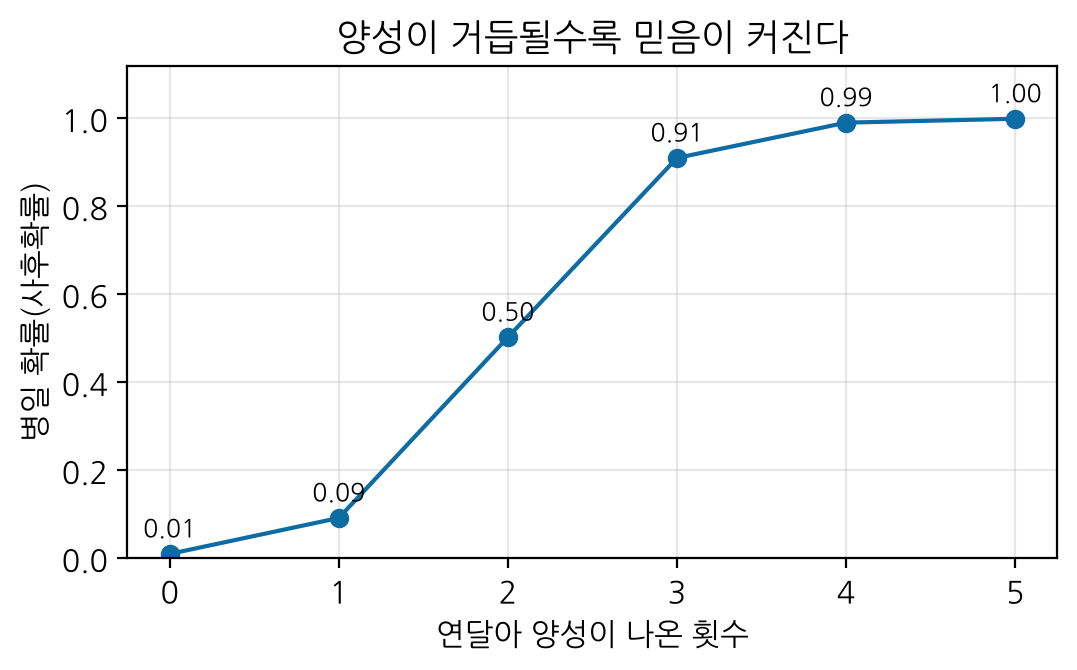

In [ ]:
import matplotlib.pyplot as plt
p, post = 0.01, [0.01]                     # 2.3의 검사: 유병률 1%
for k in range(5):                         # 다섯 번 연달아 양성
    p = bayes(p, 0.9, 0.09)
    post.append(p)
print([round(x, 3) for x in post])
plt.figure(figsize=(6, 3.2))
plt.plot(range(6), post, "o-", color="#0E6CA5")
for k, x in enumerate(post): plt.text(k, x + 0.04, f"{x:.2f}", ha="center", fontsize=9)
plt.xlabel("연달아 양성이 나온 횟수"); plt.ylabel("병일 확률(사후확률)"); plt.ylim(0, 1.12)
plt.title("양성이 거듭될수록 믿음이 커진다"); plt.grid(alpha=0.3)
plt.show()

양성 한 번으로는 9%뿐이지만, 세 번 연달아 양성이면 91%입니다. 증거 하나하나는 약해도 쌓이면 믿음이 크게 바뀝니다. 나이브 베이즈가 단어 수십 개를 곱해 판정하는 것도 같은 원리입니다. 단, 같은 사람이 같은 이유로 거짓 양성을 반복할 수 있다면(검사끼리 상관있다면) 이 계산은 믿음을 너무 키웁니다.

## 05. 파이썬 실습: 스팸 문자 가려내기

### [실습 예제 9-3 ★] 문자 데이터 불러오기와 기준선

문자 데이터를 읽어 처음 몇 통을 직접 읽어 보고, 똑같은 문자를 지운 뒤 기준선 정확도를 구하시오. 모델이 쓸 "스팸", "숫자", "길이" 열도 만드시오.

**❶ 도구 불러오기**

In [ ]:
import numpy as np                             # 수 계산
import pandas as pd                            # 표 다루기
import matplotlib.pyplot as plt                # 그래프
pd.set_option("display.width", 120)            # 표를 한 줄에 넓게 찍는다

모든 실습은 이 세 도구로 시작합니다. `as np`처럼 짧은 별명을 붙이는 것은 파이썬 사용자들의 약속이라, 다른 사람의 코드도 그대로 읽힙니다. 한글 글꼴 설정은 노트북 첫 셀에 있습니다.

**❷ 데이터 읽기**

In [ ]:
URL = ("https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/"
       "master/data/sms.tsv")
sms = pd.read_csv(URL, sep="\t", header=None, names=["label", "msg"], quoting=3)
print("모양(줄, 열):", sms.shape)
print("똑같은 문자:", sms.duplicated().sum(), "통")

모양(줄, 열): (5574, 2)
똑같은 문자: 403 통


이 파일은 칸을 탭으로 나누어서 `sep="\t"`를 씁니다. 첫 줄에 열 이름이 없어 `header=None`, `names`로 이름을 붙입니다. `quoting=3`은 "문자 속 따옴표를 그냥 글자로 읽어라"는 뜻입니다. 이것을 빼면 따옴표가 든 문자 여러 통이 한 줄로 붙어 줄 수가 줄어듭니다. 읽자마자 `shape`로 줄 수를 확인하는 습관이 이런 사고를 잡습니다.

**❸ 처음 몇 통 직접 읽어 보기**

In [ ]:
for label, msg in sms.head(6).values:          # 처음 6줄의 (label, msg)
    print(f"{label:4s} | {msg[:70]}")          # 문자는 앞 70자만

ham  | Go until jurong point, crazy.. Available only in bugis n great world l
ham  | Ok lar... Joking wif u oni...
spam | Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Te
ham  | U dun say so early hor... U c already then say...
ham  | Nah I don't think he goes to usf, he lives around here though
spam | FreeMsg Hey there darling it's been 3 week's now and no word back! I'd


모델을 만들기 전에 데이터를 눈으로 읽어야 합니다. `values`는 표를 줄 단위 묶음으로 꺼내고, `for label, msg in …`은 한 줄의 두 칸을 두 이름에 나누어 받습니다. `{label:4s}`는 네 칸 너비로 맞춰 찍으라는 뜻입니다. 스팸은 "Free entry", "FreeMsg"처럼 공짜를 앞세우고 날짜와 숫자가 많으며, 정상 문자는 "lar", "U dun say"처럼 싱가포르식 줄임말이 많습니다. 이 관찰이 [코랩 실습 9-1]·[9-5]의 "숫자 개수" 특징이 됩니다.

**❹ 중복 지우고 기준선 구하기**

In [ ]:
sms = sms.drop_duplicates().reset_index(drop=True)    # 똑같은 문자는 하나만
print(sms["label"].value_counts().to_string())
print("모두 정상이라고 찍을 때 정확도:", round((sms["label"] == "ham").mean(), 3))

label
ham     4518
spam     653
모두 정상이라고 찍을 때 정확도: 0.874


`drop_duplicates( )`는 똑같은 줄을 하나만 남기고, `reset_index(drop=True)`는 줄 번호를 0부터 다시 매깁니다. `sms["label"] == "ham"`은 줄마다 참·거짓이고, 참·거짓의 평균은 참의 비율입니다. 그래서 마지막 줄이 "모두 정상"으로 찍은 정확도, 곧 **기준선**입니다. 앞으로 만드는 모델은 모두 이 숫자와 견줍니다.

**❺ 모델이 쓸 열 만들기**

In [ ]:
sms["스팸"] = (sms["label"] == "spam").astype(int)    # 스팸이면 1, 정상이면 0
sms["숫자"] = sms["msg"].str.count(r"\d")             # 문자 속 숫자(0~9)의 개수
sms["길이"] = sms["msg"].str.len()                    # 글자 수
print(sms.groupby("label")[["숫자", "길이"]].mean().round(1))

         숫자     길이
label             
ham     0.3   70.9
spam   15.5  137.7


`astype(int)`는 참·거짓을 1·0으로 바꿉니다. 모델은 글자 대신 0과 1을 정답으로 받습니다. `str.`으로 시작하는 함수는 열의 문자열마다 한꺼번에 적용됩니다. `str.count(r"\d")`는 숫자 글자가 몇 번 나오는지 셉니다. `\d`는 "숫자 한 글자"를 뜻하는 **정규식**(글자의 모양을 나타내는 약속 기호)입니다. `groupby("label")`로 정상과 스팸을 나누어 평균을 내면, 스팸은 숫자가 50배쯤 많고 길이도 두 배쯤 깁니다.

> **[코드 읽기] `quoting=3`과 `str.count(r"\d")`**
>
> `quoting=3`은 `csv.QUOTE_NONE`과 같은 값입니다. 보통 CSV는 따옴표로 싼 칸 안의 줄바꿈과 쉼표를 한 칸으로 읽는데, 이 파일은 따옴표를 그냥 글자로 써서 그 규칙을 끄는 것입니다. 빼고 읽으면 5,574줄이 아니라 그보다 적게 읽힙니다.
>
> 정규식 앞의 `r`은 "역슬래시를 그대로 두라"는 표시입니다. `"\d"`처럼 쓰면 파이썬이 역슬래시를 먼저 해석하려 해서 경고가 납니다. 숫자 덩어리(전화번호 하나)를 세려면 `r"\d+"`를 씁니다.

**❻ 그래프로 보기: 정상과 스팸의 수, 숫자 개수의 분포**

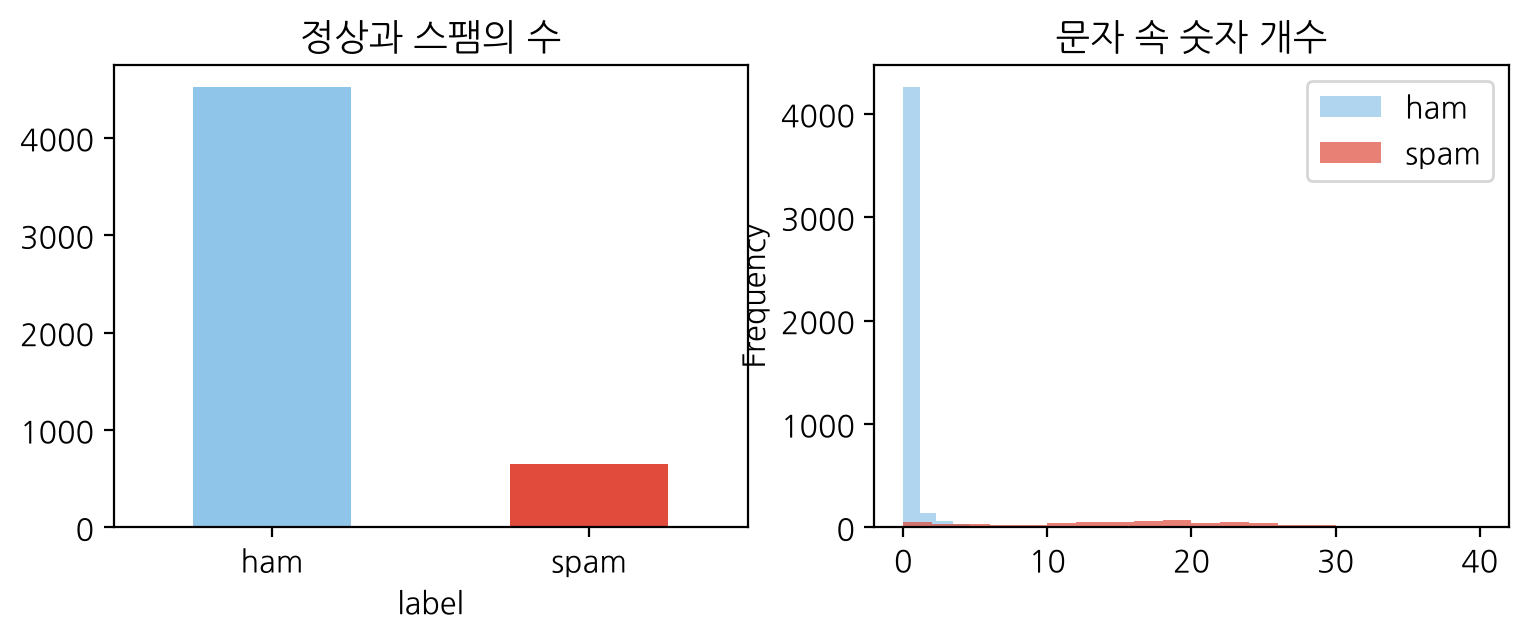

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
sms["label"].value_counts().plot.bar(ax=ax[0], color=["#8EC5E8", "#E04B3C"])
ax[0].set_title("정상과 스팸의 수"); ax[0].tick_params(axis="x", rotation=0)
for lab, col in [("ham", "#8EC5E8"), ("spam", "#E04B3C")]:
    sms.loc[sms["label"] == lab, "숫자"].clip(upper=40).plot.hist(
        ax=ax[1], bins=20, alpha=0.7, color=col, label=lab)
ax[1].set_title("문자 속 숫자 개수"); ax[1].legend()
plt.show()

`plt.subplots(1, 2)`는 한 줄에 그림 칸 두 개를 만들고, `ax=ax[0]`처럼 어느 칸에 그릴지 알려 줍니다. 오른쪽은 정상과 스팸의 **히스토그램**(값을 구간으로 나누어 센 막대)을 반투명(`alpha=0.7`)하게 겹쳐 그렸습니다. `clip(upper=40)`은 40보다 큰 값을 40으로 눌러 긴 꼬리 때문에 그림이 납작해지지 않게 합니다. 두 무리가 거의 겹치지 않으니 숫자 개수 하나로도 꽤 가를 수 있겠다는 예상이 섭니다.

> **[직접 해 보기]**
>
> ① 스팸 문자만 5통 골라 읽어 보세요. `sms[sms["스팸"] == 1]["msg"].sample(5, random_state=1)`. 숫자 말고 어떤 특징이 보이나요? ② 느낌표 개수 열을 만들어 정상과 스팸의 평균을 견주어 보세요. `sms["msg"].str.count("!")`.

### 🟣 [코랩 실습 9-1 ☆] 숫자 개수로 나누어 보기

> 이 실습은 **노트북에만** 있습니다. 책에는 할 일과 결과 미리 보기만 실었습니다.

숫자 개수를 구간으로 나누어 구간마다 문자 수와 스팸 비율을 구하고, 막대그래프로 그리시오. 길이로도 같은 표를 만들어 견주시오.

**❶ 구간으로 나누어 세기**

In [ ]:
bins = [-1, 0, 2, 5, 10, 20, 100]              # 구간의 경계
group = pd.cut(sms["숫자"], bins)               # 문자마다 어느 구간인지
table = sms.groupby(group, observed=True)["스팸"].agg(["size", "mean"])
print(table.round(3).to_string())

           size   mean
숫자                    
(-1, 0]    3842  0.010
(0, 2]      619  0.052
(2, 5]      148  0.338
(5, 10]      79  0.709
(10, 20]    285  0.979
(20, 100]   198  0.995


`pd.cut( )`은 수를 구간으로 바꿉니다. (−1, 0]은 "−1보다 크고 0 이하", 곧 숫자가 하나도 없는 문자입니다. `agg(["size", "mean"])`은 구간마다 줄 수와 평균을 한꺼번에 구합니다. "스팸" 열은 0과 1이라 평균이 곧 스팸 비율입니다. `observed=True`는 문자가 하나도 없는 구간은 빼라는 뜻입니다.

**❷ 그래프로 보기**

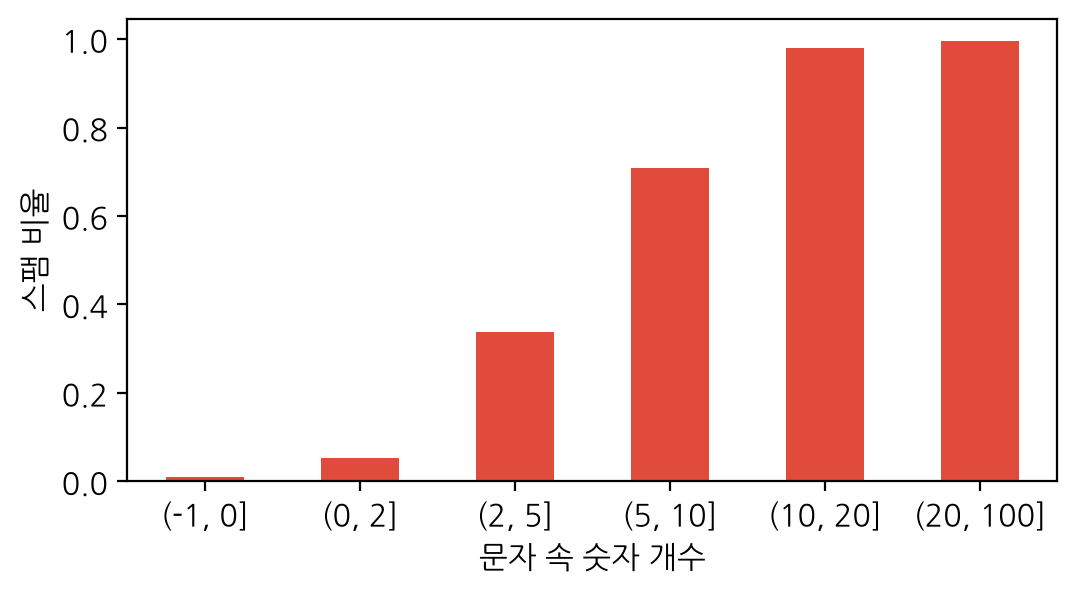

In [ ]:
table["mean"].plot.bar(color="#E04B3C", figsize=(6, 3))
plt.xlabel("문자 속 숫자 개수"); plt.ylabel("스팸 비율")
plt.xticks(rotation=0); plt.show()

0개 구간은 1%, 10개를 넘으면 98% 이상입니다. 그 사이 구간에서 비율이 가파르게 바뀌고 양 끝에서는 0과 1에 붙습니다. 이 S자 모양이 01절의 시그모이드입니다.

**❸ 길이로도 나누어 보기**

In [ ]:
len_group = pd.qcut(sms["길이"], 5)            # 문자 수가 같은 다섯 구간
print(sms.groupby(len_group, observed=True)["스팸"].agg(["size", "mean"]).round(3).to_string())

                size   mean
길이                         
(1.999, 32.0]   1053  0.004
(32.0, 48.0]    1028  0.013
(48.0, 77.0]    1042  0.027
(77.0, 134.0]   1027  0.134
(134.0, 910.0]  1021  0.460


`pd.qcut( )`은 경계를 정하지 않고 "줄 수가 같은 다섯 토막"으로 나눕니다. 길이가 긴 다섯째 토막(135자 이상)에서만 스팸 비율이 46%로 크게 오르고, 그마저 절반을 넘지 못합니다. 길이도 단서지만, 숫자 개수처럼 양 끝이 깨끗하게 갈리지는 않습니다. 단서마다 이렇게 표 하나를 만들어 보는 것이 특징을 고르는 첫걸음입니다.

> **[직접 해 보기]**
>
> 경계를 `bins = [-1, 0, 1, 3, 6, 10, 100]`로 바꾸어 표를 다시 만들어 보세요. 스팸 비율이 50%를 넘는 구간은 어디서 시작하나요? [실습 예제 9-5]에서 구할 "확률이 0.5가 되는 숫자 개수"(6.3개)와 견주어 보세요.

### [실습 예제 9-4] 로지스틱 회귀를 문자 여덟 통으로 따라 하기

실제 문자 5,171통으로 들어가기 전에, 문자 여덟 통으로 로지스틱 회귀가 하는 일을 한 걸음씩 손으로 따라 해 봅시다. ❶ 회귀식 z를 만들고 ❷ 시그모이드로 확률을 내고 ❸ 문턱값으로 판정한 뒤 ❹ 로그 손실로 계수가 좋은지 재고 ❺ 손실을 줄이는 쪽으로 계수를 고칩니다. 사이킷런의 `.fit( )` 한 줄이 속에서 하는 일이 이것입니다.

**❶ 작은 데이터 만들기**

In [ ]:
import numpy as np, pandas as pd
toy = pd.DataFrame({"숫자": [0, 1, 2, 3, 6, 8, 10, 12],
                    "스팸": [0, 0, 0, 1, 0, 1, 1, 1]})   # 예외 두 통 포함
print(toy.T)

    0  1  2  3  4  5   6   7
숫자  0  1  2  3  6  8  10  12
스팸  0  0  0  1  0  1   1   1


숫자가 많을수록 스팸이 많지만, 일부러 예외 두 통(숫자 3개인 스팸, 6개인 정상)을 넣었습니다. 실제 데이터도 깔끔하게 갈리지 않습니다.

**❷ 계수를 정해 놓고 확률 손으로 내기**

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

tb0, tb1 = -4.0, 0.8                    # 일단 정해 본 계수
toy["z"] = tb0 + tb1 * toy["숫자"]       # 회귀식
toy["확률"] = sigmoid(toy["z"])          # 0~1 확률
toy["판정"] = (toy["확률"] >= 0.5).astype(int)
print(toy.round(3))
print("맞힌 수:", (toy["판정"] == toy["스팸"]).sum(), "/ 8")

   숫자  스팸    z     확률  판정
0   0   0 -4.0  0.018   0
1   1   0 -3.2  0.039   0
2   2   0 -2.4  0.083   0
3   3   1 -1.6  0.168   0
4   6   0  0.8  0.690   1
5   8   1  2.4  0.917   1
6  10   1  4.0  0.982   1
7  12   1  5.6  0.996   1
맞힌 수: 6 / 8


숫자 0개인 문자는 z = −4, 확률 0.018입니다. 숫자 5개에서 z = 0이 되므로 "숫자 5개 이상이면 스팸"이라는 규칙이 됩니다. 예외 두 통만 틀려서 8통 가운데 6통을 맞혔습니다.

**❸ 로그 손실로 계수 견주기**

In [ ]:
def log_loss_hand(b0, b1):
    p = sigmoid(b0 + b1 * toy["숫자"])
    y = toy["스팸"]
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

for b0, b1 in [(-4.0, 0.8), (-1.0, 0.1), (0.0, 0.0)]:
    print(f"b0={b0:5.1f}, b1={b1:.1f} → 로그 손실 {log_loss_hand(b0, b1):.3f}")

b0= -4.0, b1=0.8 → 로그 손실 0.401
b0= -1.0, b1=0.1 → 로그 손실 0.591
b0=  0.0, b1=0.0 → 로그 손실 0.693


로그 손실은 실제가 1이면 −ln p, 0이면 −ln(1 − p)를 평균한 값입니다(4.1의 [더 알아보기]). (0, 0)은 모두 확률 0.5를 주는 "모르겠다" 모델로, 손실 0.693이 기준입니다. 손실이 작은 (−4, 0.8)이 더 좋은 계수입니다.

**❹ 손실을 줄이는 쪽으로 계수 고치기(경사하강법)**

In [ ]:
b0, b1, lr = 0.0, 0.0, 0.05             # lr: 한 걸음의 크기
x, y = toy["숫자"].values, toy["스팸"].values
for step in range(1, 3001):
    p = sigmoid(b0 + b1 * x)
    b0 -= lr * np.mean(p - y)           # 기울기 반대로 한 걸음
    b1 -= lr * np.mean((p - y) * x)
    if step in (1, 10, 100, 1000, 3000):
        loss = log_loss_hand(b0, b1)
        print(f"{step:5d}걸음: b0={b0:6.2f}, b1={b1:5.2f}, 손실 {loss:.3f}")

    1걸음: b0=  0.00, b1= 0.08, 손실 0.611
   10걸음: b0= -0.07, b1= 0.17, 손실 0.571
  100걸음: b0= -0.71, b1= 0.25, 손실 0.476
 1000걸음: b0= -2.43, b1= 0.51, 손실 0.376
 3000걸음: b0= -2.70, b1= 0.55, 손실 0.374


`p - y`는 "확률이 정답보다 얼마나 높은가"입니다. 너무 높게 준 문자가 많으면 계수를 내리고, 너무 낮게 준 문자가 많으면 올립니다. 한 걸음씩 고칠 때마다 손실이 줄어 0.4 밑으로 내려갑니다. 사이킷런은 이보다 빠른 방법으로 같은 일을 합니다. `max_iter`가 이 걸음 수의 최댓값입니다.

**❺ 사이킷런 답과 맞춰 보고 그림 그리기**

사이킷런: b0=-2.71, b1=0.55


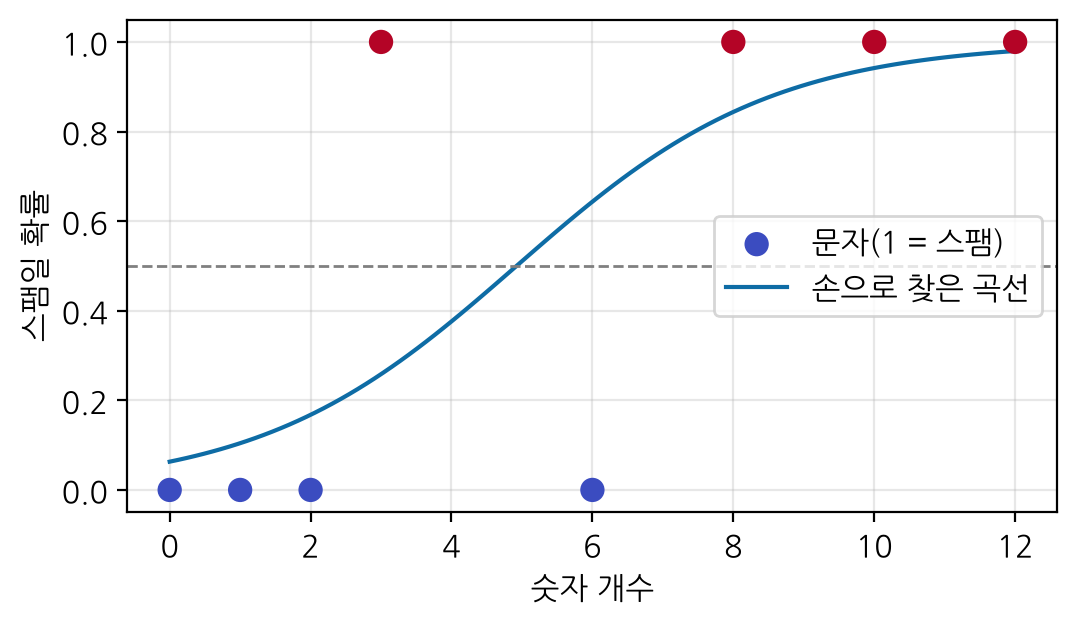

In [ ]:
from sklearn.linear_model import LogisticRegression
tm = LogisticRegression(C=1e6)          # C를 크게: 규제 거의 없이
tm.fit(toy[["숫자"]], toy["스팸"])
print(f"사이킷런: b0={tm.intercept_[0]:.2f}, b1={tm.coef_[0][0]:.2f}")
import matplotlib.pyplot as plt
xs = np.linspace(0, 12, 100)
plt.figure(figsize=(6, 3.2))
plt.scatter(toy["숫자"], toy["스팸"], s=60, c=toy["스팸"],
            cmap="coolwarm", zorder=3, label="문자(1 = 스팸)")
plt.plot(xs, sigmoid(b0 + b1 * xs), color="#0E6CA5", label="손으로 찾은 곡선")
plt.axhline(0.5, ls="--", color="gray", lw=1)
plt.xlabel("숫자 개수"); plt.ylabel("스팸일 확률")
plt.legend(loc="center right"); plt.grid(alpha=0.3)
plt.show()

손으로 3,000걸음 간 계수가 사이킷런의 답에 거의 다가갔습니다. 걸음을 더 가면 같아집니다. 이제 [실습 예제 9-5]에서 같은 일을 문자 3,878통으로 합니다. 데이터가 커져도 하는 일은 ❶~❺ 그대로입니다.

### [실습 예제 9-5 ★] 숫자 개수 하나로 로지스틱 회귀

문자를 훈련용과 시험용으로 나누고, 숫자 개수 하나로 로지스틱 회귀를 맞추시오. 오즈비와 확률이 0.5가 되는 숫자 개수를 구하고, 문자 세 통의 확률을 직접 계산해 모델의 답과 맞춰 보시오.

**❶ 훈련과 시험으로 나누기**

In [ ]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(sms, test_size=0.25, random_state=42,
                               stratify=sms["스팸"])          # 스팸 비율을 지키며 나눈다
print("훈련", len(train), "통 / 시험", len(test), "통")
print("스팸 비율: 훈련", round(train["스팸"].mean(), 3), "/ 시험", round(test["스팸"].mean(), 3))

훈련 3878 통 / 시험 1293 통
스팸 비율: 훈련 0.126 / 시험 0.126


`test_size=0.25`는 25%를 시험용으로 떼라는 뜻입니다. `random_state=42`는 무작위로 섞는 순서를 고정해, 누가 언제 돌려도 같은 결과가 나오게 합니다. `stratify`는 3.3의 층화 추출로, 두 토막의 스팸 비율을 똑같이 맞춥니다. 시험 문자는 마지막 채점에만 씁니다.

**❷ 로지스틱 회귀 맞추고 계수 읽기**

In [ ]:
from sklearn.linear_model import LogisticRegression
one = LogisticRegression().fit(train[["숫자"]], train["스팸"])
b0, b1 = one.intercept_[0], one.coef_[0][0]
print(f"절편 {b0:.2f}, 기울기 {b1:.3f}, 오즈비 {np.exp(b1):.2f}")
print("확률이 0.5가 되는 숫자 개수:", round(-b0 / b1, 1))

절편 -4.06, 기울기 0.643, 오즈비 1.90
확률이 0.5가 되는 숫자 개수: 6.3


`train[["숫자"]]`처럼 대괄호를 두 겹 쓰면 열 하나짜리 표(2차원)가 됩니다. 사이킷런은 X를 늘 표로 받습니다. `intercept_`에 절편, `coef_`에 기울기가 들어 있고, `np.exp(b1)`이 e^(b₁), 곧 오즈비입니다. 숫자가 하나 늘 때마다 오즈가 1.9배가 됩니다. 확률 0.5는 z = 0인 곳이므로 b₀ + b₁x = 0을 풀면 x = −b₀ ÷ b₁입니다.

**❸ (식 9-1)로 확률 직접 계산하기**

In [ ]:
for k in [0, 2, 5, 10, 15]:
    p = 1 / (1 + np.exp(-(b0 + b1 * k)))       # 시그모이드
    print(f"숫자 {k:2d}개 → 스팸일 확률 {p:.3f}")

숫자  0개 → 스팸일 확률 0.017
숫자  2개 → 스팸일 확률 0.059
숫자  5개 → 스팸일 확률 0.302
숫자 10개 → 스팸일 확률 0.915
숫자 15개 → 스팸일 확률 0.996


(식 9-1)을 그대로 한 줄로 옮겼습니다. `{p:.3f}`는 소수점 아래 셋째 자리까지 찍으라는 뜻입니다. 숫자 5개와 10개 사이에서 확률이 0.30에서 0.92로 뛰어오릅니다.

**❹ 모델에게 직접 물어 맞춰 보기**

In [ ]:
three = test[["msg", "숫자"]].head(3)
three["모델 확률"] = one.predict_proba(three[["숫자"]])[:, 1].round(3)
three["판정"] = one.predict(three[["숫자"]])
three["msg"] = three["msg"].str[:40]
print(three.to_string())

                                           msg  숫자  모델 확률  판정
3125  RCT' THNQ Adrian for U text. Rgds Vatian   0  0.017   0
2829  I'll text carlos and let you know, hang    0  0.017   0
2272  A Boy loved a gal. He propsd bt she didn   4  0.185   0


`predict_proba( )`는 문자마다 (정상일 확률, 스팸일 확률) 두 칸을 돌려주고, `[:, 1]`은 둘째 칸입니다. 숫자 0개는 ❸의 손 계산 0.017과 같고, 숫자 4개는 1 ÷ (1 + e· ≈ 0.18(연습문제 9-2)과 같습니다. 그런데 첫 문자는 실제로 스팸입니다. 숫자가 없으니 이 모델에게는 정상으로 보일 수밖에 없습니다. `predict( )`는 그 확률이 0.5 이상이면 1, 아니면 0입니다. 모델의 답을 식으로 다시 계산해 맞춰 보면, 모델이 "무엇을 하는지" 손에 잡힙니다.

**❺ 특징을 하나 더: 숫자와 길이**

In [ ]:
two = LogisticRegression(max_iter=1000).fit(train[["숫자", "길이"]], train["스팸"])
for name, m, cols in [("숫자 하나", one, ["숫자"]), ("숫자+길이", two, ["숫자", "길이"])]:
    print(f"{name}: 시험 정확도 {m.score(test[cols], test['스팸']):.3f}")
print("숫자+길이의 계수:", two.coef_[0].round(3), " 오즈비:", np.exp(two.coef_[0]).round(3))

숫자 하나: 시험 정확도 0.974
숫자+길이: 시험 정확도 0.972
숫자+길이의 계수: [0.612 0.006]  오즈비: [1.845 1.006]


열 이름을 리스트로 늘리기만 하면 특징이 둘인 모델이 됩니다. `score( )`는 정확도를 바로 돌려줍니다. 길이의 오즈비 1.006은 글자 하나당이라 1에 가깝지만, 글자 50개면 1.006 ≈ 1.35배로 쌓입니다. 그런데 정확도는 오히려 0.974에서 0.972로 내렸습니다. 스팸은 길면서 숫자도 많아, 길이는 숫자 개수와 겹치는 정보를 거의 새로 보태지 못했습니다. **특징을 늘린다고 늘 좋아지지는 않습니다.** 무엇이 달라졌는지는 [실습 예제 9-6]에서 혼동행렬로 나누어 봅니다.

**❻ 그래프로 보기: 숫자 개수와 스팸일 확률**

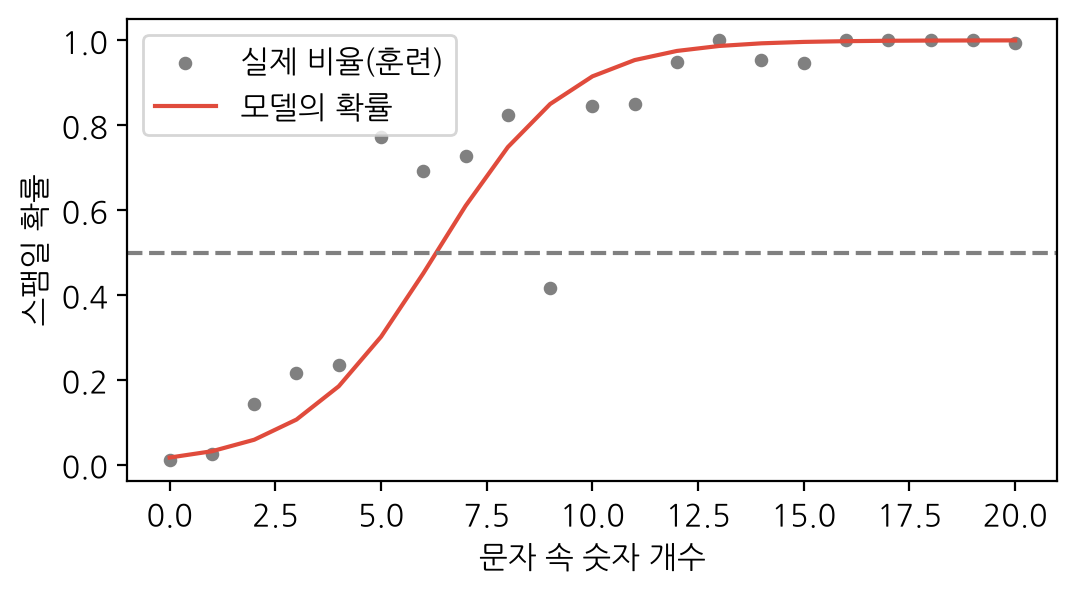

In [ ]:
x = np.arange(0, 21)                           # 숫자 0개부터 20개까지
p = 1 / (1 + np.exp(-(b0 + b1 * x)))           # 한꺼번에 계산
rate = train.groupby(train["숫자"].clip(upper=20))["스팸"].mean()   # 실제 스팸 비율
plt.figure(figsize=(6, 3))
plt.scatter(rate.index, rate.values, color="gray", s=15, label="실제 비율(훈련)")
plt.plot(x, p, color="#E04B3C", label="모델의 확률")
plt.axhline(0.5, color="gray", linestyle="--")  # 문턱값 0.5
plt.xlabel("문자 속 숫자 개수"); plt.ylabel("스팸일 확률"); plt.legend(); plt.show()

❸에서는 다섯 값을 하나씩 계산했지만, 넘파이 배열 `x`를 넣으면 21개 값을 한 줄로 계산합니다. 회색 점은 훈련 문자에서 숫자 개수마다 실제로 스팸이었던 비율입니다. 곡선이 점들을 따라가면 모델이 데이터를 잘 요약한 것입니다. `axhline( )`은 가로선을 긋습니다. 곡선이 점선을 넘는 곳(6.3개)이 판정이 바뀌는 자리입니다.

> **[코드 읽기] f-문자열의 `:.3f`**
>
> `f"…{p:.3f}"`처럼 따옴표 앞에 f를 붙이면 중괄호 안의 값을 글자 속에 끼워 넣습니다. 콜론 뒤는 모양입니다. `.3f`는 소수점 아래 셋째 자리, `2d`는 두 칸 너비의 정수, `.1%`는 백분율 소수 한 자리입니다(0.874 → 87.4%).

> **[직접 해 보기]**
>
> ① `random_state=42`를 7로 바꾸어 다시 나누고 맞추어 보세요. 기울기와 0.5 지점이 얼마나 바뀌나요? ② `stratify`를 빼고 나누면 시험 문자의 스팸 비율이 어떻게 되나요?

### [실습 예제 9-6 ★] 혼동행렬과 정밀도, 재현율

숫자 개수 모델로 시험 문자를 판정하고, 혼동행렬과 네 가지 점수를 구하시오. 네 칸으로 점수를 손으로 다시 계산하고, 놓친 스팸을 직접 읽어 보시오.

**❶ 판정하고 혼동행렬 세기**

In [ ]:
from sklearn.metrics import confusion_matrix
pred = one.predict(test[["숫자"]])             # 문턱값 0.5로 판정한 0, 1
y = test["스팸"]                               # 정답
print(confusion_matrix(y, pred))               # [[TN FP] [FN TP]]

[[1128    2]
 [  31  132]]


`predict( )`는 확률이 0.5 이상이면 1, 아니면 0을 돌려줍니다. 사이킷런의 혼동행렬은 줄이 실제(위 정상, 아래 스팸), 칸이 판정(왼쪽 정상, 오른쪽 스팸)입니다. 그래서 오른쪽 위가 헛경보(FP), 왼쪽 아래가 놓침(FN)입니다. 책의 그림(1.3)과 줄 순서가 다를 수 있으니, 처음 볼 때는 늘 "줄이 실제인가"부터 확인합니다.

**❷ 네 가지 점수 구하기**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print("정확도", round(accuracy_score(y, pred), 3), " 정밀도", round(precision_score(y, pred), 3))
print("재현율", round(recall_score(y, pred), 3), " F1", round(f1_score(y, pred), 3))

정확도 0.974  정밀도 0.985
재현율 0.81  F1 0.889


네 함수 모두 (정답, 판정) 순서로 넣습니다. 순서를 바꾸면 정밀도와 재현율이 뒤바뀝니다. 함수가 (식 9-3)과 같은 값을 낸다는 것은 [실습 예제 9-1]에서 손 계산과 맞춰 보았습니다.

**❸ 놓친 스팸 읽어 보기**

In [ ]:
missed = test[(y == 1) & (pred == 0)]          # 실제 스팸인데 정상이라고 한 문자
print("놓친 스팸", len(missed), "통, 숫자 개수 평균", round(missed["숫자"].mean(), 1))
for msg in missed["msg"].head(4):
    print("-", msg[:75])

놓친 스팸 31 통, 숫자 개수 평균 2.5
- RCT' THNQ Adrian for U text. Rgds Vatian
- Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1
- important information 4 orange user . today is your lucky day!2find out why
- Orange brings you ringtones from all time Chart Heroes, with a free hit eac


조건 두 개를 `&`로 잇고 각 조건은 괄호로 쌉니다. 놓친 스팸은 숫자가 거의 없는 스팸입니다. 숫자 개수만 보는 모델은 이런 스팸을 원리적으로 잡을 수 없습니다. 숫자 말고 "단어"를 봐야 한다는 결론이 여기서 나오고, [실습 예제 9-8]로 이어집니다. 점수를 본 뒤에는 틀린 사례를 읽는 것, 이것을 **오류 분석**이라고 합니다.

**❹ 그래프로 보기: 혼동행렬 그림**

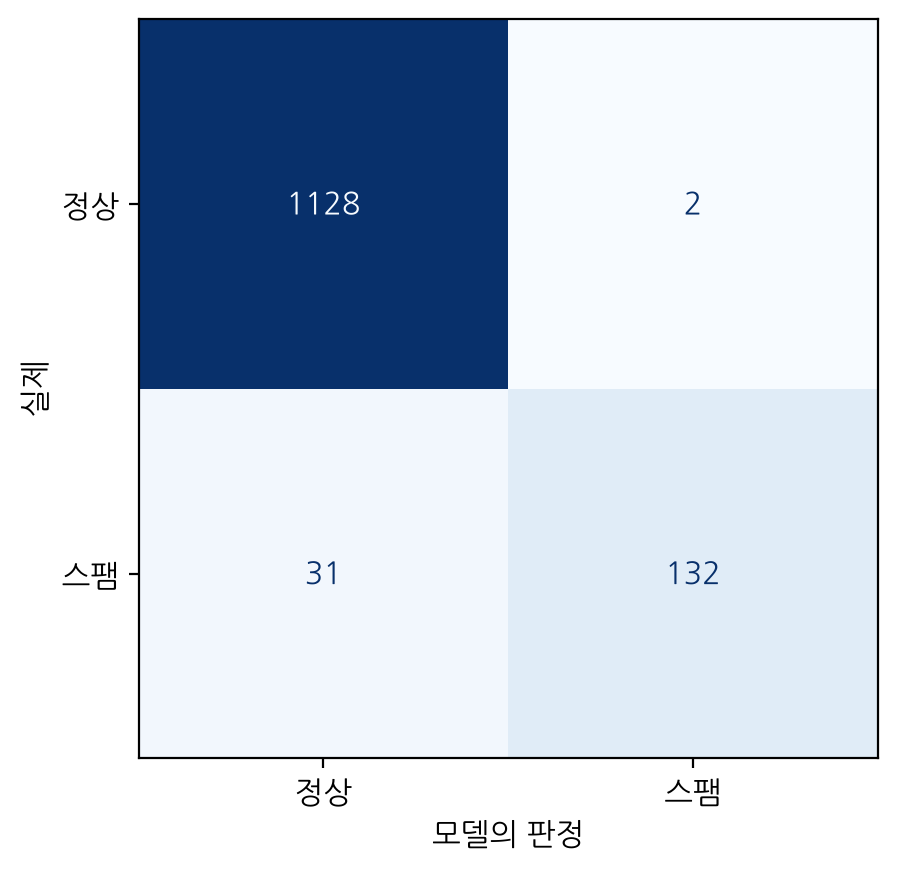

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["정상", "스팸"],
                                        cmap="Blues", colorbar=False)
plt.xlabel("모델의 판정"); plt.ylabel("실제"); plt.show()

`from_predictions(정답, 판정)`은 혼동행렬을 세어 칸마다 색을 칠해 줍니다. 수가 클수록 짙습니다. `display_labels`로 0과 1 대신 "정상", "스팸"이라고 씁니다.

> **[직접 해 보기]**
>
> [실습 예제 9-5]의 ❺에서 만든 "숫자+길이" 모델 `two`로 ❶~❸을 다시 해 보세요. `pred2 = two.predict(test[["숫자", "길이"]])`. 헛경보와 놓침 가운데 어느 쪽이 줄었나요?

### [실습 예제 9-7] 나이브 베이즈를 문자 네 통으로 따라 하기

나이브 베이즈가 새 문자를 판정하는 과정을 문자 네 통으로 따라 해 봅시다. ❶ 범주별로 단어를 세고 ❷ 라플라스 스무딩으로 단어 확률을 내고 ❸ 사전확률에 단어 확률을 곱해 견주고 ❹ 사이킷런의 답과 맞춰 봅니다. (식 9-6)과 (식 9-7)을 그대로 코드로 옮긴 것입니다.

**❶ 범주별로 단어 세기**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
train4 = ["free prize call", "free call now",
          "call me later", "see you later"]
lab4 = np.array([1, 1, 0, 0])           # 1 = 스팸
cv4 = CountVectorizer().fit(train4)
X4 = cv4.transform(train4).toarray()
cnt = pd.DataFrame({"스팸": X4[lab4 == 1].sum(axis=0),     # 스팸 줄만 더하기
                    "정상": X4[lab4 == 0].sum(axis=0)},
                   index=cv4.get_feature_names_out())
print(cnt.T)

    call  free  later  me  now  prize  see  you
스팸     2     2      0   0    1      1    0    0
정상     1     0      2   1    0      0    1    1


스팸 두 통과 정상 두 통입니다. 단어 주머니를 만든 뒤 범주별로 열을 더하면, 단어마다 "스팸에서 몇 번, 정상에서 몇 번"이 나옵니다. "free"는 스팸에만 2번, "later"는 정상에만 2번, "call"은 양쪽에 다 있습니다.

**❷ 라플라스 스무딩으로 단어 확률 내기**

In [ ]:
V = len(cnt)                            # 단어 종류 수
prob4 = (cnt + 1) / (cnt.sum() + V)     # (식 9-7), α = 1
print("단어 종류", V, "/ 범주별 단어 수", cnt.sum().to_dict())
print(prob4.round(3).T)

단어 종류 8 / 범주별 단어 수 {'스팸': 6, '정상': 6}
     call   free  later     me    now  prize    see    you
스팸  0.214  0.214  0.071  0.071  0.143  0.143  0.071  0.071
정상  0.143  0.071  0.214  0.143  0.071  0.071  0.143  0.143


스팸 쪽 단어는 6개, 단어 종류는 8개이므로 분모는 6 + 8 = 14입니다. "free"는 (2 + 1) ÷ 14 ≈ 0.214, 스팸에 한 번도 없던 "later"도 (0 + 1) ÷ 14 ≈ 0.071로 0이 아닙니다. 스무딩 덕분입니다.

**❸ 새 문자 판정: 사전확률 × 단어 확률**

In [ ]:
new = ["free", "call", "later"]         # 새 문자
prior = {"스팸": 0.5, "정상": 0.5}        # 사전확률
score = {c: prior[c] * np.prod([prob4.loc[w, c] for w in new]) for c in prior}
total = sum(score.values())
for c in score:
    terms = " × ".join(f"{prob4.loc[w, c]:.3f}" for w in new)
    print(f"{c}: {prior[c]} × {terms} = {score[c]:.5f} → 확률 {score[c] / total:.3f}")

스팸: 0.5 × 0.214 × 0.214 × 0.071 = 0.00164 → 확률 0.600
정상: 0.5 × 0.071 × 0.143 × 0.214 = 0.00109 → 확률 0.400


범주마다 사전확률에 단어 확률 세 개를 곱합니다(식 9-6). "free"는 스팸 쪽을, "later"는 정상 쪽을, "call"은 스팸 쪽을 조금 더 밉니다(0.214 대 0.143). 두 점수를 합이 1이 되게 나누면 확률입니다. 스팸 쪽이 크니 스팸으로 판정합니다.

**❹ 사이킷런의 답과 맞춰 보기**

In [ ]:
from sklearn.naive_bayes import MultinomialNB
nb4 = MultinomialNB(alpha=1.0).fit(X4, lab4)
pp = nb4.predict_proba(cv4.transform(["free call later"]))
print("사이킷런 [정상, 스팸] 확률:", pp.round(3))

사이킷런 [정상, 스팸] 확률: [[0.4 0.6]]


손으로 구한 확률과 같습니다. `MultinomialNB`가 하는 일은 ❶~❸이 전부입니다. [실습 예제 9-8]에서는 같은 일을 문자 3,878통, 단어 7,395종으로 합니다. 단어가 수십 개인 문자는 아주 작은 수를 수십 번 곱하게 되어 0으로 뭉개지므로, 사이킷런은 확률 대신 로그를 더합니다(곱의 로그 = 로그의 합).

### [실습 예제 9-8 ★] 단어로 판정하기: 나이브 베이즈와 로지스틱 회귀

문자를 단어 주머니로 바꾸고, 나이브 베이즈와 로지스틱 회귀의 성적을 숫자 개수 모델과 견주시오.

**❶ 작은 예로 단어 주머니 보기**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
toy = ["Free entry, call now", "Call me later", "free free prize"]
v = CountVectorizer().fit(toy)
print("사전:", list(v.get_feature_names_out()))
print(v.transform(toy).toarray())

사전: ['call', 'entry', 'free', 'later', 'me', 'now', 'prize']
[[1 1 1 0 0 1 0]
 [1 0 0 1 1 0 0]
 [0 0 2 0 0 0 1]]


문자 세 통으로 먼저 원리를 봅니다. `CountVectorizer`는 글자를 소문자로 바꾸고, 두 글자 이상의 단어로 자른 뒤, 나온 단어를 가나다(알파벳)순으로 늘어놓아 **사전**(열)을 만듭니다. 표의 한 줄이 문자 한 통, 한 칸이 그 단어가 나온 횟수입니다. 셋째 문자의 "free" 칸이 2인 것을 확인하세요. 낱말의 순서는 버리고 횟수만 남기므로 "단어 주머니"입니다.

**❷ 문자 전체를 단어 주머니로 바꾸기**

In [ ]:
vec = CountVectorizer()                        # 단어마다 몇 번 나왔는지 센다
A_tr = vec.fit_transform(train["msg"])         # 훈련 문자로 단어 사전을 만들고 센다
A_te = vec.transform(test["msg"])              # 시험 문자는 같은 사전으로 센다
print("훈련 문자표:", A_tr.shape, "/ 시험 문자표:", A_te.shape)
print("0이 아닌 칸의 비율:", round(A_tr.nnz / (A_tr.shape[0] * A_tr.shape[1]), 4))

훈련 문자표: (3878, 7395) / 시험 문자표: (1293, 7395)
0이 아닌 칸의 비율: 0.0018


`fit_transform( )`은 훈련 문자에 나온 단어로 사전을 만들고 횟수를 셉니다. 시험 문자는 `transform( )`만 씁니다. 시험 문자로 사전을 다시 만들면 시험의 정보가 학습에 새어 들기 때문입니다(8장의 데이터 누수). 칸이 7,395개지만 한 문자에는 단어가 십여 개뿐이라 0이 아닌 칸은 0.2%도 안 됩니다. 그래서 사이킷런은 0이 아닌 칸만 적어 두는 **희소행렬**로 저장합니다(`nnz`는 0이 아닌 칸 수).

**❸ 두 모델 배우기**

In [ ]:
from sklearn.naive_bayes import MultinomialNB
nb = MultinomialNB().fit(A_tr, train["스팸"])                  # 나이브 베이즈
lr = LogisticRegression(max_iter=2000).fit(A_tr, train["스팸"])  # 로지스틱 회귀
print("나이브 베이즈가 센 단어 수(정상, 스팸):", nb.feature_count_.sum(axis=1).astype(int))

나이브 베이즈가 센 단어 수(정상, 스팸): [44083 11460]


`MultinomialNB`는 단어 횟수로 쓰는 나이브 베이즈이고, 라플라스 스무딩(α = 1)이 기본으로 들어 있습니다. `feature_count_`에는 정상과 스팸 문자에서 단어마다 센 횟수가 들어 있어, (식 9-7)의 count(w, c)를 직접 볼 수 있습니다. 로지스틱 회귀는 계수가 7,395개라 답을 찾는 데 걸음이 많이 들어서 `max_iter`(최대 걸음 수)를 늘려 줍니다.

**❹ 세 모델 같은 잣대로 채점하기**

In [ ]:
rows = []
for name, m, X in [("숫자 개수 하나", one, test[["숫자"]]),
                   ("나이브 베이즈", nb, A_te), ("로지스틱 회귀", lr, A_te)]:
    pr = m.predict(X)
    rows.append([name, accuracy_score(y, pr), precision_score(y, pr),
                 recall_score(y, pr), f1_score(y, pr)])
result = pd.DataFrame(rows, columns=["모델", "정확도", "정밀도", "재현율", "F1"])
print(result.round(3).to_string(index=False))

      모델   정확도   정밀도   재현율    F1
숫자 개수 하나 0.974 0.985 0.810 0.889
 나이브 베이즈 0.983 0.949 0.914 0.931
 로지스틱 회귀 0.977 0.972 0.840 0.901


(이름, 모델, 넣을 표) 세 쌍을 차례로 꺼내 같은 네 점수를 잽니다. 한 줄씩 리스트에 모아 표로 만들면 성적표가 됩니다. 정확도는 셋 다 97~98%로 비슷하지만, 재현율은 나이브 베이즈가 91.4%로 가장 높습니다. [표 9-2]의 숫자가 그대로 나옵니다. 단어를 보니 숫자 없는 스팸도 잡힌 것입니다.

**❺ 그래프로 보기: 정확도와 재현율 나란히**

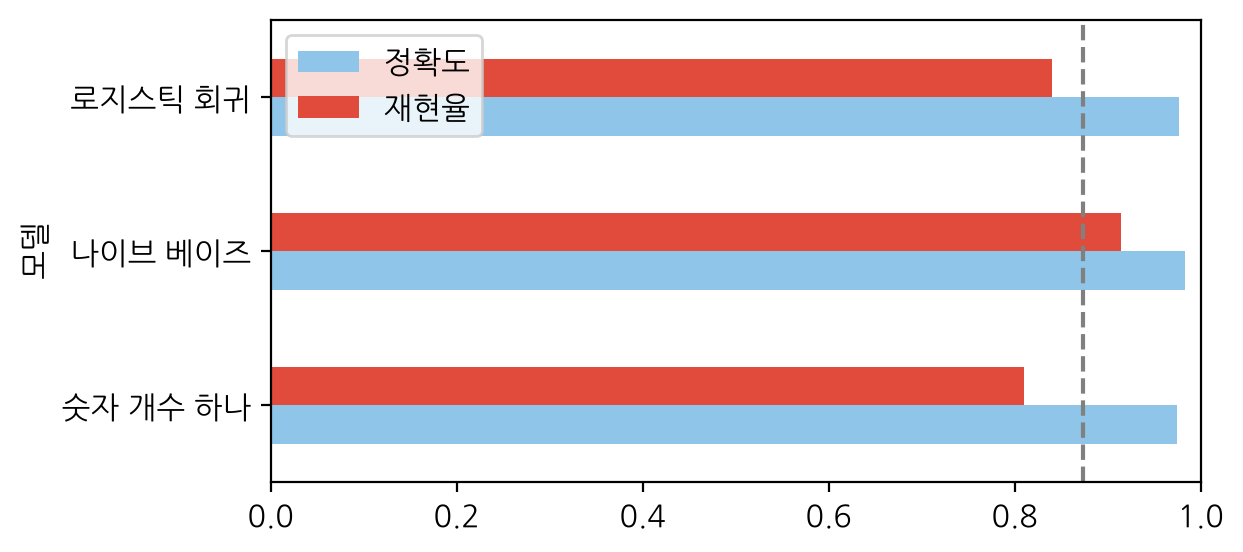

In [ ]:
result.set_index("모델")[["정확도", "재현율"]].plot.barh(figsize=(6, 3),
                                                    color=["#8EC5E8", "#E04B3C"])
plt.axvline(0.874, color="gray", linestyle="--")   # 기준선: 모두 정상이라고 찍기
plt.xlim(0, 1); plt.show()

`set_index("모델")`은 모델 이름을 줄 이름으로 올려 막대 이름표가 되게 합니다. `barh`는 가로 막대입니다. 기준선을 점선(`axvline`)으로 함께 그리면, 정확도 막대는 모두 기준선 바로 위에 붙어 있고 재현율에서 차이가 난다는 것이 한눈에 보입니다.

> **[직접 해 보기]**
>
> ① `CountVectorizer(stop_words="english")`로 "the", "to" 같은 흔한 영어 낱말을 빼고 다시 채점해 보세요. ② `MultinomialNB(alpha=0.1)`처럼 스무딩을 줄이면 재현율과 정밀도가 어떻게 바뀌나요?

### [실습 예제 9-9 ★] 문턱값 바꾸기

로지스틱 회귀의 확률을 받아 문턱값을 0.1에서 0.9까지 바꾸며 헛경보, 놓침, 손해(헛경보 × 10 + 놓침)를 구하시오. 손해가 가장 작은 문턱값을 코드로 고르시오.

**❶ 확률 받기**

In [ ]:
prob = lr.predict_proba(A_te)[:, 1]            # 둘째 열 = 스팸일 확률
print(prob[:5].round(3))
print("확률 0.5 이상인 문자:", (prob >= 0.5).sum(), "통 / predict()의 스팸 판정:", lr.predict(A_te).sum(), "통")

[0.089 0.037 0.001 0.007 0.017]
확률 0.5 이상인 문자: 141 통 / predict()의 스팸 판정: 141 통


`predict_proba( )`는 문자마다 (정상일 확률, 스팸일 확률) 두 칸을 돌려줍니다. `[:, 1]`은 "모든 줄의 둘째 칸"입니다. 둘째 줄은 `predict( )`가 "확률 0.5 이상"과 똑같은 판정이라는 것을 확인합니다.

**❷ 문턱값마다 세기**

In [ ]:
rows = []
for th in [0.1, 0.3, 0.5, 0.7, 0.9]:
    tn, fp, fn, tp = confusion_matrix(y, (prob >= th).astype(int)).ravel()
    rows.append([th, fp, fn, 10 * fp + fn])
cost = pd.DataFrame(rows, columns=["문턱값", "헛경보", "놓침", "손해"])
print(cost.to_string(index=False))

 문턱값  헛경보  놓침  손해
 0.1   24  15 255
 0.3    7  21  91
 0.5    4  26  66
 0.7    3  33  63
 0.9    0  50  50


`prob >= th`가 "문턱값 이상이면 스팸"이라는 판정입니다. 문턱값을 올리면 스팸 판정이 깐깐해져 헛경보는 24통에서 0통으로 줄고, 놓침은 15통에서 50통으로 늡니다. 손해의 식에서 헛경보에 10을 곱한 것은 "중요한 문자를 스팸함에 넣는 일이 스팸 하나를 놓치는 일보다 열 배 나쁘다"는 판단입니다.

**❸ 손해가 가장 작은 문턱값 고르기**

In [ ]:
best = cost.loc[cost["손해"].idxmin()]         # 손해가 가장 작은 줄
print("고른 문턱값:", best["문턱값"], " 손해:", int(best["손해"]))
for w in [1, 10]:                              # 헛경보의 무게를 바꾸면?
    c = w * cost["헛경보"] + cost["놓침"]
    print(f"헛경보 × {w:2d}: 고른 문턱값 {cost.loc[c.idxmin(), '문턱값']}")

고른 문턱값: 0.9  손해: 50
헛경보 ×  1: 고른 문턱값 0.3
헛경보 × 10: 고른 문턱값 0.9


`idxmin( )`은 가장 작은 값이 있는 줄 이름을, `loc[ ]`는 그 줄을 꺼냅니다. 헛경보를 열 배로 치면 0.9, 두 틀림을 같게 치면 0.3이 고릅니다. 문턱값은 모델이 아니라 **틀림의 값어치**가 정합니다. 여기서는 설명을 위해 시험 문자로 골랐지만, 실제로는 3.5의 [잠깐만]처럼 검증 데이터로 고르고 시험 문자는 마지막에 한 번만 씁니다(미니 프로젝트 3단계).

**❹ 그래프로 보기: 문턱값에 따른 헛경보와 놓침**

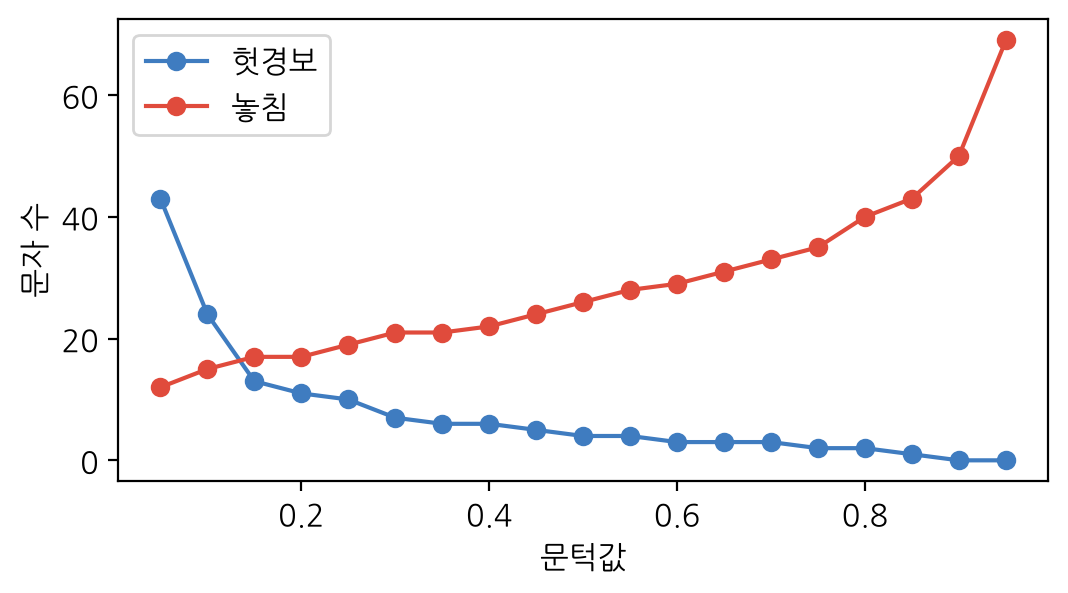

In [ ]:
ths = np.linspace(0.05, 0.95, 19)              # 0.05부터 0.95까지 19개
fp_n = [((prob >= t) & (y == 0)).sum() for t in ths]
fn_n = [((prob < t) & (y == 1)).sum() for t in ths]
plt.figure(figsize=(6, 3))
plt.plot(ths, fp_n, marker="o", color="#3F7CC0", label="헛경보")
plt.plot(ths, fn_n, marker="o", color="#E04B3C", label="놓침")
plt.xlabel("문턱값"); plt.ylabel("문자 수"); plt.legend(); plt.show()

❷는 다섯 점만 봤지만, `np.linspace( )`로 문턱값 19개를 촘촘히 만들고 리스트 내포(`[… for t in ths]`)로 한꺼번에 셉니다. 혼동행렬을 만들지 않고 조건 두 개를 `&`로 이어 바로 세었습니다. 두 선이 엇갈리는 맞바꿈이 한눈에 보입니다. 어느 쪽을 줄일지는 그래프가 아니라 손해의 식이 정합니다.

> **[직접 해 보기]**
>
> 피싱 문자 차단처럼 놓침이 헛경보보다 다섯 배 나쁘다면 손해 = 헛경보 + 5 × 놓침입니다. ❸의 코드를 고쳐 문턱값을 골라 보세요(연습문제 9-5).

### [실습 예제 9-10 ★] 모델이 배운 단어 들여다보기

로지스틱 회귀의 계수가 가장 큰 단어와 가장 작은 단어를 찾고, "lor", "da", `&lt;#&gt;`가 스팸과 정상 문자에 몇 번 나오는지 세시오. 한 문자의 판정을 단어별 점수로 풀어 보시오.

**❶ 계수로 단어 줄 세우기**

In [ ]:
words = vec.get_feature_names_out()            # 열 순서대로 단어 이름
order = np.argsort(lr.coef_[0])                # 계수가 작은 것부터의 순서
print("정상 쪽:", list(words[order[:8]]))
print("스팸 쪽:", list(words[order[-8:]][::-1]))

정상 쪽: ['my', 'gt', 'lt', 'me', 'at', 'that', 'him', 'but']
스팸 쪽: ['txt', 'reply', 'text', 'call', 'new', 'free', 'chat', 'uk']


단어마다 계수가 하나씩 있습니다. `np.argsort( )`는 값을 작은 것부터 늘어놓았을 때의 자리 번호를 돌려줍니다. 앞 8개는 계수가 가장 작은(정상 쪽) 단어, 뒤 8개는 가장 큰(스팸 쪽) 단어입니다. `[::-1]`은 순서를 뒤집어 가장 큰 것부터 보이게 합니다.

**❷ 의심스러운 표시 세기**

In [ ]:
low = sms["msg"].str.lower()                   # 대소문자를 같게
for w in ["lor", "da", "&lt;#&gt;"]:
    has = low.str.contains(w, regex=False) if w.startswith("&") else low.str.contains(rf"\b{w}\b")
    print(f"'{w}' 든 문자: 스팸 {has[sms['스팸'] == 1].sum()}통, 정상 {has[sms['스팸'] == 0].sum()}통")

'lor' 든 문자: 스팸 0통, 정상 142통
'da' 든 문자: 스팸 0통, 정상 126통
'&lt;#&gt;' 든 문자: 스팸 0통, 정상 197통


`\b`는 정규식에서 "단어의 경계"입니다. `\bda\b`는 "today" 속의 da는 빼고 "da"라는 단어만 찾습니다. 기호 `&lt;#&gt;`는 정규식으로 읽지 않도록 `regex=False`로 그대로 찾습니다. 세 표시는 모두 정상 문자에만 나옵니다. 정상 문자는 싱가포르 대학생 문자, 스팸은 영국 게시판에서 모았기 때문입니다. 모델이 "스팸의 특징"이 아니라 **데이터의 출신**을 배웠다는 3.6의 이야기를 코드로 확인한 것입니다.

**❸ 한 문자의 판정을 단어별로 풀어 보기**

In [ ]:
i = int(np.argmax(prob))                       # 스팸 확률이 가장 높은 시험 문자
row = A_te[i].toarray()[0]                     # 그 문자의 단어 횟수
used = np.nonzero(row)[0]                      # 나온 단어의 열 번호
part = pd.Series(lr.coef_[0][used] * row[used], index=words[used]).sort_values(ascending=False)
print(test["msg"].iloc[i][:80])
print(part.head(6).round(2).to_string())
print("절편", round(lr.intercept_[0], 2), "+ 단어 점수 합", round(part.sum(), 2), "= z")

We tried to call you re your reply to our sms for a video mobile 750 mins UNLIMI
reply     3.59
call      3.47
text      1.77
free      1.44
mobile    1.32
to        1.02
절편 -4.84 + 단어 점수 합 17.99 = z


로지스틱 회귀의 z는 "절편 + 계수 × 횟수"의 합이므로, 한 문자의 z를 단어별 몫으로 나눌 수 있습니다. `np.argmax( )`는 가장 큰 값의 자리, `np.nonzero( )`는 0이 아닌 칸의 자리입니다. 어떤 단어가 판정을 끌어올렸는지 보이면, 모델의 판정을 사람에게 설명할 수 있습니다.

**❹ 그래프로 보기: 양쪽 끝 단어 열 개**

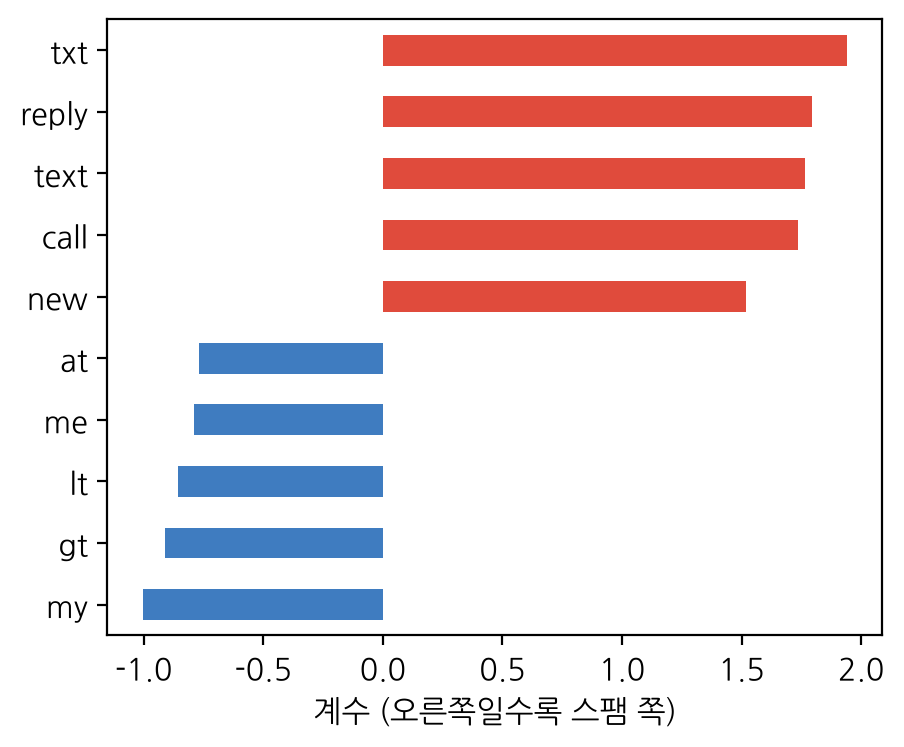

In [ ]:
idx = list(order[:5]) + list(order[-5:])       # 정상 쪽 5개 + 스팸 쪽 5개
top = pd.Series(lr.coef_[0][idx], index=words[idx])
top.plot.barh(color=["#3F7CC0"] * 5 + ["#E04B3C"] * 5, figsize=(5, 4))
plt.xlabel("계수 (오른쪽일수록 스팸 쪽)"); plt.show()

`pd.Series(값, index=이름)`은 이름표가 붙은 열을 만듭니다. 막대 색을 리스트로 주어 정상 쪽은 파랑, 스팸 쪽은 빨강으로 칠했습니다. 계수가 0에서 멀수록 판정에 크게 작용하는 단어입니다.

> **[직접 해 보기]**
>
> 나이브 베이즈는 계수 대신 단어의 로그 확률을 가집니다. `nb.feature_log_prob_[1] - nb.feature_log_prob_[0]`이 큰 단어 8개를 뽑아 ❶의 스팸 쪽 단어와 견주어 보세요.

### 🟣 [코랩 실습 9-2 ☆] 데이터가 적을 때는 누가 이기나

> 이 실습은 **노트북에만** 있습니다. 책에는 할 일과 결과 미리 보기만 실었습니다.

훈련 문자를 50통, 200통, 1,000통으로 줄여 열 번씩 다시 배우고, 두 모델의 평균 F1을 견주시오.

**❶ 한 번 해 보기: 훈련 문자 200통**

In [ ]:
small = train.sample(200, random_state=0)      # 훈련 문자 가운데 200통만
v2 = CountVectorizer().fit(small["msg"])
for name, m in [("나이브 베이즈", MultinomialNB()),
                ("로지스틱 회귀", LogisticRegression(max_iter=2000))]:
    m.fit(v2.transform(small["msg"]), small["스팸"])
    print(name, "F1", round(f1_score(y, m.predict(v2.transform(test["msg"]))), 3))
print("200통 속 스팸:", small["스팸"].sum(), "통")

나이브 베이즈 F1 0.756
로지스틱 회귀 F1 0.568
200통 속 스팸: 23 통


`sample(200)`은 무작위로 200줄을 뽑습니다. 사전도 그 200통으로 새로 만듭니다. 시험 문자는 그대로 1,293통으로 채점합니다.

**❷ 크기마다 열 번씩 되풀이하기**

In [ ]:
def f1_small(n, seed):
    s = train.sample(n, random_state=seed)
    v = CountVectorizer().fit(s["msg"])
    out = []
    for m in [MultinomialNB(), LogisticRegression(max_iter=2000)]:
        m.fit(v.transform(s["msg"]), s["스팸"])
        out.append(f1_score(y, m.predict(v.transform(test["msg"]))))
    return out

rows = []
for n in [50, 200, 1000]:
    scores = np.array([f1_small(n, seed) for seed in range(10)])   # 10번 × 2모델
    rows.append([n, *scores.mean(axis=0).round(3), *scores.std(axis=0).round(3)])
small_res = pd.DataFrame(rows, columns=["훈련 문자 수", "나이브 베이즈 F1", "로지스틱 F1",
                                        "NB 표준편차", "LR 표준편차"])
print(small_res.to_string(index=False))

 훈련 문자 수  나이브 베이즈 F1  로지스틱 F1  NB 표준편차  LR 표준편차
      50       0.601    0.127    0.170    0.121
     200       0.797    0.581    0.039    0.059
    1000       0.892    0.835    0.015    0.027


같은 일을 여러 번 하므로 함수(`def`)로 묶었습니다. `f1_small(n, seed)`는 "n통을 seed로 뽑아 두 모델의 F1을 돌려준다"입니다. 크기마다 seed 0~9로 열 번 불러 평균(`mean`)과 표준편차(`std`)를 냅니다. `*`는 배열의 두 값을 풀어 리스트에 넣습니다.

문자 50통이면 스팸은 6통 남짓입니다. 로지스틱 회귀는 거의 모두 정상으로 판정해 F1이 바닥이고, 횟수만 세는 나이브 베이즈는 훨씬 높습니다. 표준편차도 작은 데이터에서 큽니다. **데이터가 적을 때는 가정이 강한 단순한 모델이 버팁니다.** 1,000통이면 차이가 줄어듭니다.

**❸ 그래프로 보기: 훈련 문자 수와 F1**

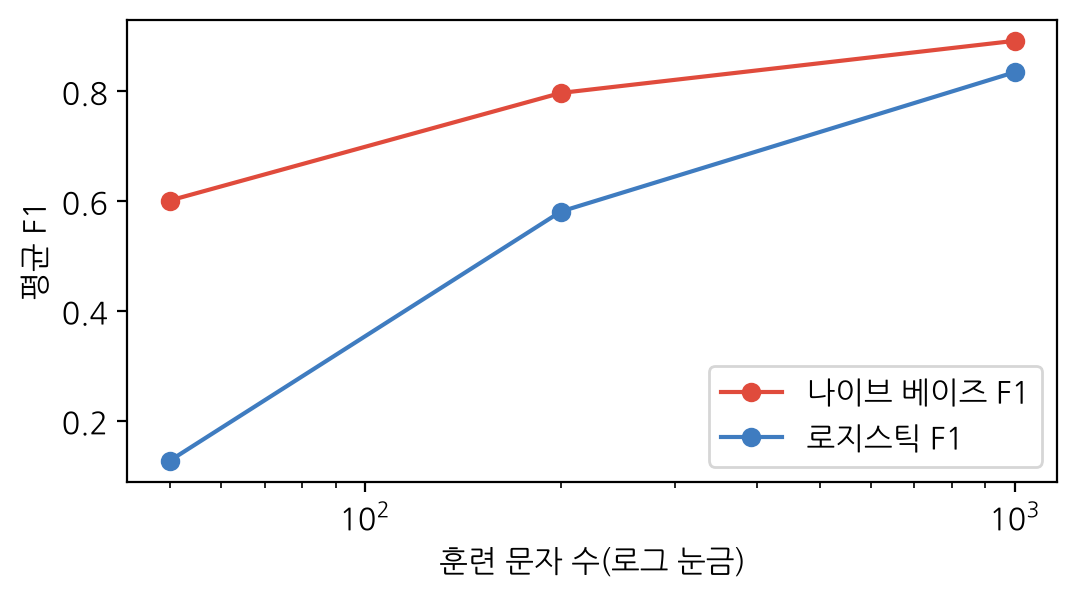

In [ ]:
plt.figure(figsize=(6, 3))
for col, c in [("나이브 베이즈 F1", "#E04B3C"), ("로지스틱 F1", "#3F7CC0")]:
    plt.plot(small_res["훈련 문자 수"], small_res[col], marker="o", color=c, label=col)
plt.xscale("log"); plt.xlabel("훈련 문자 수(로그 눈금)"); plt.ylabel("평균 F1")
plt.legend(); plt.show()

`xscale("log")`는 가로축을 로그 눈금으로 바꿉니다. 50, 200, 1,000처럼 몇 배씩 커지는 값을 고르게 펼쳐 보여 줍니다. 데이터 양에 따른 성적을 그린 이런 그림을 **학습 곡선**이라고 합니다.

### 🟣 [코랩 실습 9-3 ☆] ROC 곡선과 AUC

> 이 실습은 **노트북에만** 있습니다. 책에는 할 일과 결과 미리 보기만 실었습니다.

숫자 개수 모델과 단어 로지스틱 회귀, 나이브 베이즈의 AUC를 구하고 ROC 곡선을 그리시오.

**❶ 세 모델의 확률과 AUC**

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
probs = {"숫자 개수 하나": one.predict_proba(test[["숫자"]])[:, 1],
         "로지스틱 회귀(단어)": prob,
         "나이브 베이즈(단어)": nb.predict_proba(A_te)[:, 1]}
for name, pr in probs.items():
    print(f"{name:12s} AUC {roc_auc_score(y, pr):.3f}")

숫자 개수 하나     AUC 0.965
로지스틱 회귀(단어)  AUC 0.982
나이브 베이즈(단어)  AUC 0.983


딕셔너리(`{이름: 값}`)에 세 모델의 확률을 모아 두면 이름과 함께 꺼내 쓰기 좋습니다. `roc_auc_score( )`에는 판정(0, 1)이 아니라 **확률**을 넣는 것이 핵심입니다. AUC는 "스팸 하나와 정상 하나를 뽑았을 때 스팸에 더 높은 확률을 줄 가능성"이라, 문턱값을 정하지 않고도 모델끼리 견줄 수 있습니다.

**❷ 곡선 위의 한 점 읽기**

In [ ]:
fpr, tpr, th = roc_curve(y, prob)              # 문턱값마다 (헛경보 비율, 재현율)
k = np.argmin(np.abs(th - 0.5))                # 문턱값 0.5에 가장 가까운 점
print(f"문턱값 {th[k]:.2f}: 헛경보 비율 {fpr[k]:.3f}, 재현율 {tpr[k]:.3f}")
print("곡선의 점 수:", len(th))

문턱값 0.51: 헛경보 비율 0.004, 재현율 0.840
곡선의 점 수: 62


`roc_curve( )`는 문턱값을 높은 데서 낮은 데로 내리며 (헛경보 비율, 재현율)의 짝을 돌려줍니다. 문턱값 0.5의 점은 [실습 예제 9-9]의 표(헛경보 4통 ÷ 정상 1,130통, 재현율 0.84)와 같습니다. ROC 곡선은 문턱값마다 한 번씩 그린 혼동행렬을 이은 것입니다.

**❸ 그래프로 보기: ROC 곡선**

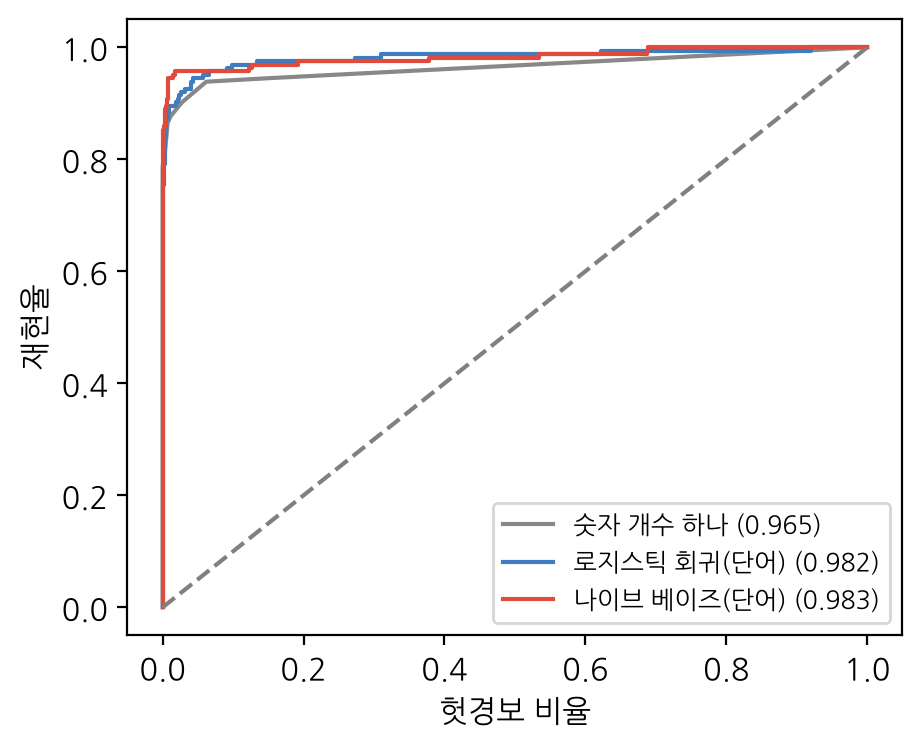

In [ ]:
plt.figure(figsize=(5, 4))
for (name, pr), c in zip(probs.items(), ["#888888", "#3F7CC0", "#E04B3C"]):
    f, t, _ = roc_curve(y, pr)
    plt.plot(f, t, color=c, label=f"{name} ({roc_auc_score(y, pr):.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")   # 찍기 수준
plt.xlabel("헛경보 비율"); plt.ylabel("재현율"); plt.legend(fontsize=9); plt.show()

`zip( )`은 두 목록을 한 칸씩 짝지어 줍니다. 대각선 점선은 아무렇게나 찍을 때(AUC 0.5)입니다. 판정(0, 1)을 넣으면 점 하나뿐인 곡선이 되니, 반드시 확률을 넣습니다.

### [실습 예제 9-11 ★] 틀린 문자 읽기와 새 문자 판정

나이브 베이즈가 틀린 시험 문자를 읽어 보고, 직접 쓴 새 문자를 판정하시오. 전처리와 모델을 파이프라인 하나로 묶어 쓰시오.

**❶ 헛경보와 놓침 읽어 보기**

In [ ]:
pred_nb = nb.predict(A_te)
p_nb = nb.predict_proba(A_te)[:, 1]
for kind, mask in [("헛경보", (y == 0) & (pred_nb == 1)), ("놓침", (y == 1) & (pred_nb == 0))]:
    print(f"[{kind}] {mask.sum()}통")
    for msg, p in zip(test["msg"][mask].head(3), p_nb[mask.values][:3]):
        print(f"  {p:.2f} | {msg[:65]}")

[헛경보] 8통
  0.84 | Unlimited texts. Limited minutes.
  0.52 | Received, understood n acted upon!
  0.69 | 26th OF JULY
[놓침] 14통
  0.42 | Burger King - Wanna play footy at a top stadium? Get 2 Burger Kin
  0.00 | Missed call alert. These numbers called but left no message. 0700
  0.00 | Money i have won wining number 946 wot do i do next


`mask`는 줄마다 참·거짓인 거름망입니다. `test["msg"][mask]`는 참인 줄만 남깁니다. 넘파이 배열(`p_nb`)에는 `mask.values`로 같은 거름망을 씁니다. 헛경보는 "Unlimited texts"처럼 요금제 광고에 흔한 낱말이 든 문자나 "26th OF JULY"처럼 짧은 정상 문자입니다. 놓침은 "Missed call alert", "Money i have won"처럼 스팸인데 정상 문자에 흔한 낱말로 쓴 문자라 확률이 0에 가깝습니다. 숫자로 본 점수(헛경보 8, 놓침 14) 뒤에 이런 문자가 있습니다.

**❷ 파이프라인으로 묶기**

In [ ]:
from sklearn.pipeline import make_pipeline
spam_filter = make_pipeline(CountVectorizer(), MultinomialNB())
spam_filter.fit(train["msg"], train["스팸"])    # 글자를 그대로 넣는다
print("시험 F1:", round(f1_score(y, spam_filter.predict(test["msg"])), 3))

시험 F1: 0.931


`make_pipeline( )`은 "단어 주머니 → 나이브 베이즈"를 한 모델로 묶습니다. `fit( )`에 문자 글자를 그대로 넣으면 안에서 사전을 만들고 세고 배우며, `predict( )`도 글자를 받습니다. [실습 예제 9-8]의 ❷·❸을 손으로 할 때와 F1이 같습니다. 사전을 훈련 문자로만 만드는 규칙이 저절로 지켜져 누수가 없습니다([실습 예제 9-8]의 [머신러닝 개념] 상자).

**❸ 새 문자 판정하기**

In [ ]:
new = ["Congratulations! You have won a free prize. Call 09061701461 now",
       "Are we still meeting for lunch tomorrow?",
       "URGENT: your account is locked, reply with your PIN",
       "Free parking near the station today",
       "Sorry, I'll call you later"]
for msg, p in zip(new, spam_filter.predict_proba(new)[:, 1]):
    print(f"{p:.3f} {'스팸' if p >= 0.5 else '정상'} | {msg}")

1.000 스팸 | Congratulations! You have won a free prize. Call 09061701461 now
0.000 정상 | Are we still meeting for lunch tomorrow?
0.993 스팸 | URGENT: your account is locked, reply with your PIN
0.041 정상 | Free parking near the station today
0.000 정상 | Sorry, I'll call you later


직접 쓴 문자 다섯 통입니다. 상금과 전화번호가 든 첫 문자는 스팸, 점심 약속은 정상입니다. "free"가 든 넷째 문자는 "parking", "station", "today"처럼 정상 쪽 낱말이 더 많아 0.04로 정상입니다. 셋째 문자는 "URGENT", "reply"가 스팸 쪽이라 0.99입니다. 모델은 단어의 뜻이 아니라 데이터에서 그 단어가 어느 쪽에 많이 나왔는지만 압니다. 한국어 문자는 이 모델의 사전에 없는 낱말이라 판정할 수 없습니다. 모델은 배운 데이터의 언어와 세상 안에서만 작동합니다.

> **[직접 해 보기]**
>
> ① 여러분이 받은 스팸 문자를 영어로 옮겨 `new`에 넣어 보세요. ② `spam_filter`의 `MultinomialNB()`를 `LogisticRegression(max_iter=2000)`으로 바꾸면 넷째 문자의 확률이 어떻게 바뀌나요?

## [미니 프로젝트 9] 날씨만 보고 서울 초미세먼지 "나쁨"을 맞힐 수 있을까

**질문.** 천식이 있는 친구에게 "지금은 마스크를 꼭 쓰세요" 알림을 보내는 앱을 만든다고 합시다. 서울의 날씨만 보고 초미세먼지(PM2.5)가 "나쁨"인 시각을 맞힐 수 있을까요?

**데이터.** 강의 자료의 두 파일(서울 PM2.5 시간 평균 29,184시각, 서울 관측소 날씨)을 코랩 파일 창에 올려 씁니다. 평균이 35㎍/㎥를 넘는 시각을 "나쁨"으로 셉니다(환경부 예보 등급의 "나쁨"은 36부터). 원자료를 직접 받아 줄이는 방법(에어코리아의 24시는 다음 날 0시로 바꿈)은 노트북의 "☆ 원자료 정리" 셀에 있습니다.


> **[더 알아보기] ☆ 에어코리아에서 직접 받아 줄이기**
>
> 에어코리아 누리집의 확정자료는 달마다 엑셀 파일이 하나씩이고, 한 파일에 전국 측정소의 한 달 기록이 약 48만 행 들어 있습니다. 강의 자료의 파일은 그 가운데 서울의 도시대기 측정소만 골라 시각마다 평균한 것입니다. 도로변 측정소 15곳은 자동차 바로 옆의 공기를 재므로 뺐습니다. 에어코리아는 하루를 01시~24시로 적으므로, 00시~23시로 적는 날씨 파일과 맞추려면 24시를 다음 날 00시로 넘겨야 합니다. 날씨는 기상자료개방포털의 "종관기상관측(ASOS) 시간자료"에서 서울(108)을 골라 받습니다. 여러 번 나누어 받았다면 위아래로 잇고(`pd.concat`), 같은 시각은 하나만 남깁니다(`drop_duplicates`).

**1단계: 데이터 신원 확인**([실습 예제 9-3] 응용). 두 파일을 읽어 같은 시각끼리 합치고, "나쁨" 열을 만든 뒤 달마다 "나쁨" 비율을 구하시오.

In [ ]:
# 파일 창에 미니 프로젝트의 두 CSV를 올리지 않았다면, 이 셀이 올릴 창을 엽니다.
import os
if not all(os.path.exists(f) for f in ['에어코리아_서울_도시대기평균_시간별_2023_2026.csv', 'asos_서울108_시간자료_2023_2026.csv']):
    from google.colab import files
    files.upload()

In [ ]:
AIR = "에어코리아_서울_도시대기평균_시간별_2023_2026.csv"   # 코랩 파일 창에 올린 두 파일
WEA = "asos_서울108_시간자료_2023_2026.csv"
air = pd.read_csv(AIR, parse_dates=["일시"])
wea = pd.read_csv(WEA, parse_dates=["일시"])
print("초미세먼지:", air.shape, air["일시"].min(), "~", air["일시"].max())
print(air[["측정일시", "일시"]].iloc[22:24].to_string(index=False))  # 24시 = 다음 날 0시
print("날씨:", wea.shape, " 빈칸:", wea.isna().sum().to_dict())

초미세먼지: (29184, 4) 2023-01-01 01:00:00 ~ 2026-05-01 00:00:00
      측정일시                  일시
2023010123 2023-01-01 23:00:00
2023010124 2023-01-02 00:00:00
날씨: (33241, 7)  빈칸: {'지점': 0, '지점명': 0, '일시': 0, '기온(°C)': 0, '강수량(mm)': 29375, '풍속(m/s)': 68, '습도(%)': 0}


`parse_dates=["일시"]`는 "2023-01-01 01:00" 같은 글자를 날짜·시각으로 읽습니다. 그래야 `.dt.month`, `.dt.year`로 달과 해를 꺼낼 수 있습니다. 둘째 줄은 원자료의 "2023010124"(24시)가 "2023-01-02 00:00"으로 바뀌어 있는지 확인합니다. 날씨의 빈칸은 강수량에 몰려 있습니다.

In [ ]:
wea.columns = ["지점", "지점명", "일시", "기온", "강수량", "풍속", "습도"]
wea["강수량"] = wea["강수량"].fillna(0)              # 비가 오지 않은 시각은 빈칸이다
air = air.merge(wea[["일시", "기온", "강수량", "풍속", "습도"]], on="일시")  # 같은 시각끼리
air["나쁨"] = (air["PM25"] > 35).astype(int)         # 예보 등급의 "나쁨"은 36㎍/㎥부터
print("합친 표:", air.shape, " 나쁨 비율:", round(air["나쁨"].mean(), 3))
month = air.groupby(air["일시"].dt.month)["나쁨"].mean()
print(month.round(3).to_dict())

합친 표: (29184, 9)  나쁨 비율: 0.114
{1: 0.207, 2: 0.233, 3: 0.309, 4: 0.121, 5: 0.056, 6: 0.047, 7: 0.045, 8: 0.004, 9: 0.006, 10: 0.008, 11: 0.078, 12: 0.117}


열 이름의 단위 기호(°C, mm)는 코드에서 다루기 번거로워 짧은 이름으로 바꿉니다. 강수량의 빈칸은 "비가 오지 않음"이라 0으로 채우고, 풍속의 빈칸은 진짜로 빠진 기록이라 그대로 둡니다. 같은 빈칸도 뜻이 다릅니다(3장). `merge(…, on="일시")`는 두 표에서 같은 시각의 줄끼리 옆으로 붙입니다. "나쁨"은 11.4%이지만 3월은 30.9%, 8~10월은 1%에도 못 미칩니다.

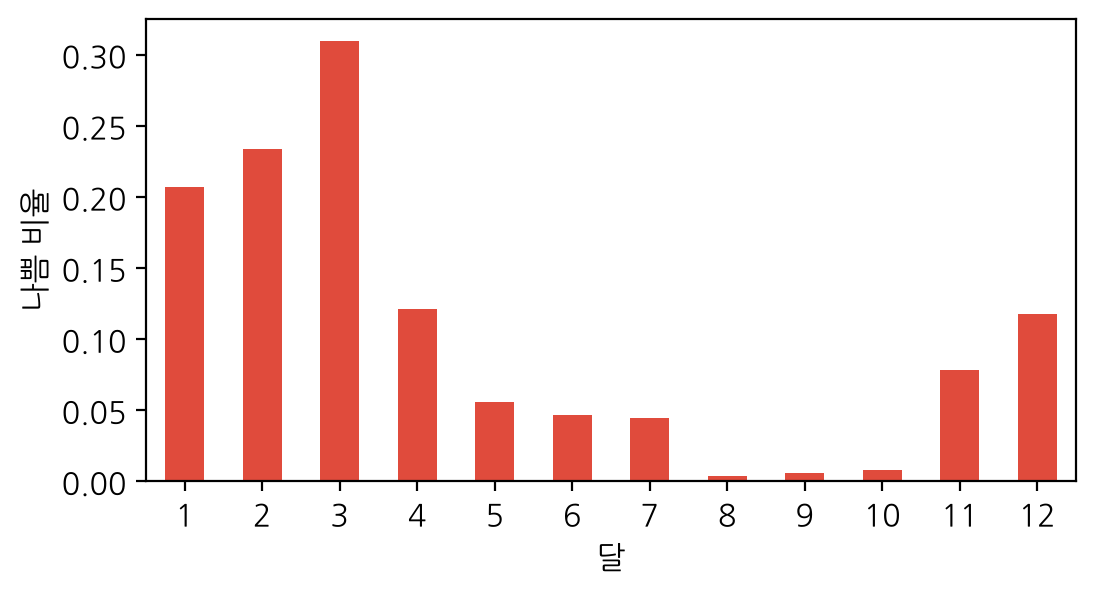

In [ ]:
month.plot.bar(color="#E04B3C", figsize=(6, 3))
plt.xlabel("달"); plt.ylabel("나쁨 비율"); plt.xticks(rotation=0); plt.show()

**2단계: 기준선과 모델**([실습 예제 9-5], [9-8] 응용). 그 시각까지 24시간의 평균 날씨로 변수를 만드시오. 2023년으로 배우고, 2024년으로 문턱값을 고르고, 2025년 1월~2026년 4월로 시험하도록 나누시오.

In [ ]:
air["1시간전"] = air["PM25"].shift(1)              # 바로 앞 시각의 농도 (4단계에서 씀)
for c in ["기온", "습도", "풍속"]:                  # 그 시각까지 24시간의 평균
    air[c + "24"] = air[c].rolling(24).mean()
air["비24"] = (air["강수량"].rolling(24).sum() > 0).astype(int)  # 24시간 안에 비가 왔나
m = air["일시"].dt.month
air["겨울"] = m.isin([12, 1, 2]).astype(int)
air["봄"] = m.isin([3, 4, 5]).astype(int)           # 여름과 가을이 기준
X_COLS = ["기온24", "습도24", "풍속24", "비24", "겨울", "봄"]
air = air.dropna(subset=X_COLS)                     # 처음 23시각, 바람 기록이 빠진 때
yr = air["일시"].dt.year
past, valid, future = air[yr == 2023], air[yr == 2024], air[yr >= 2025]
print("훈련", len(past), "/ 검증", len(valid), "/ 시험", len(future), "시각")
yt = future["나쁨"]
print("시험 기간 나쁨 비율:", round(yt.mean(), 3), " 기준선(늘 괜찮음):", round(1 - yt.mean(), 3))

훈련 8676 / 검증 8723 / 시험 11641 시각
시험 기간 나쁨 비율: 0.136  기준선(늘 괜찮음): 0.864


`shift(1)`은 열을 한 칸 아래로 밀어 "바로 앞 시각의 값"을 만듭니다. `rolling(24).mean( )`은 그 시각까지 24시간의 평균입니다. 계절은 "겨울", "봄" 두 열(0·1)로 나타내고 여름·가을을 기준으로 둡니다. 시간 데이터는 무작위로 섞지 않고 **시간 순서로** 나눕니다. 미래로 과거를 맞히는 셈이 되면 안 되기 때문입니다.

> **[잠깐만요] 이동 평균과 표준화**
>
> **이동 평균** `rolling(24).mean( )`은 각 줄에서 바로 앞 24줄(자기 포함)을 묶어 평균합니다. 창문을 한 칸씩 밀며 평균을 내는 셈이라 "이동" 평균입니다. 주가의 20일 평균선, 일주일 평균 확진자 수도 이것입니다.
>
> **표준화** `StandardScaler( )`는 열마다 평균을 빼고 표준편차로 나누어(4장의 z-점수) 단위를 맞춥니다. 단위가 다른 변수(℃, %, m/s)를 함께 넣을 때 씁니다. `make_pipeline( )`은 "표준화 → 모델"을 한 묶음으로 만들어, 표준화에 쓸 평균을 훈련 데이터에서만 구하게 해 줍니다.

In [ ]:
from sklearn.preprocessing import StandardScaler
air_m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
air_m.fit(past[X_COLS], past["나쁨"])
pt = air_m.predict_proba(future[X_COLS])[:, 1]
print("로지스틱 회귀(문턱값 0.5) 정확도:", round(accuracy_score(yt, pt >= 0.5), 3),
      " 재현율:", round(recall_score(yt, pt >= 0.5), 3))
print(pd.Series(air_m[-1].coef_[0], index=X_COLS).round(2).to_dict())

로지스틱 회귀(문턱값 0.5) 정확도: 0.874  재현율: 0.145
{'기온24': -0.4, '습도24': 0.6, '풍속24': -1.2, '비24': -0.46, '겨울': 0.89, '봄': 1.08}


`air_m[-1]`은 파이프라인의 마지막 칸, 곧 로지스틱 회귀입니다. 표준화한 뒤의 계수라 크기를 서로 견줄 수 있습니다. 기온이 낮고 습도가 높고 바람이 약하고 비가 오지 않을수록, 겨울·봄일수록 "나쁨" 쪽입니다. 바람(−1.2)이 가장 큰 단서입니다. 그런데 정확도 87.4%는 기준선 86.4%보다 1%p 남짓 높을 뿐이고, 재현율은 14.5%입니다. 날씨만으로는 "나쁨"을 거의 못 잡습니다.

**3단계: 문턱값 고르기**([실습 예제 9-9] 응용). 천식 알림에서는 놓침이 헛경보보다 세 배 나쁘다고 합시다. 검증 기간(2024년)에서 손해(놓침 × 3 + 헛경보)가 가장 작은 문턱값을 고르고, 그 문턱값으로 시험 기간을 한 번만 판정하시오.

In [ ]:
pv = air_m.predict_proba(valid[X_COLS])[:, 1]       # 검증 기간(2024년)의 확률
yv = valid["나쁨"]
rows = []
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    tn, fp, fn, tp = confusion_matrix(yv, (pv >= th).astype(int)).ravel()
    rows.append([th, fp, fn, 3 * fn + fp])
air_cost = pd.DataFrame(rows, columns=["문턱값", "헛경보", "놓침", "손해"])
print(air_cost.to_string(index=False))
print("알림을 한 번도 보내지 않으면 손해:", 3 * yv.sum())
best = air_cost.loc[air_cost["손해"].idxmin(), "문턱값"]
print("검증으로 고른 문턱값:", best)

 문턱값  헛경보  놓침   손해
 0.1 2459 126 2837
 0.2 1404 281 2247
 0.3  790 391 1963
 0.4  416 539 2033
 0.5  176 611 2009
 0.6   82 682 2128
알림을 한 번도 보내지 않으면 손해: 2175
검증으로 고른 문턱값: 0.3


[실습 예제 9-9]과 같은 코드를 **검증 기간**에 씁니다. 시험 기간은 아직 건드리지 않습니다.

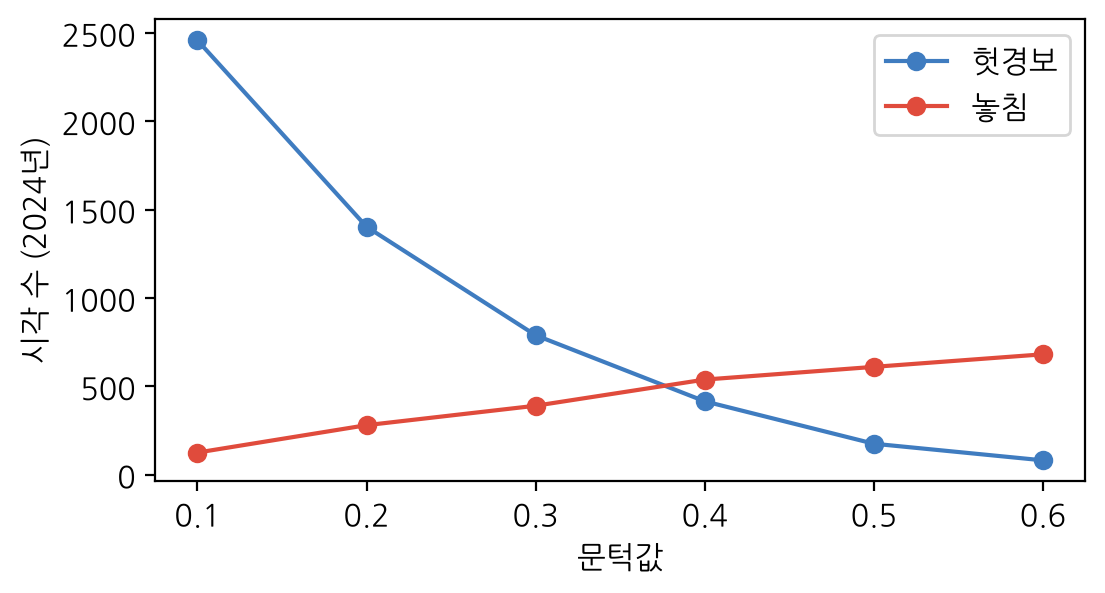

In [ ]:
air_cost.plot(x="문턱값", y=["헛경보", "놓침"], marker="o", figsize=(6, 3),
              color=["#3F7CC0", "#E04B3C"])
plt.ylabel("시각 수 (2024년)"); plt.show()

In [ ]:
plans = {"알림 안 보냄": np.zeros(len(yt), int), "늘 알림": np.ones(len(yt), int),
         "문턱값 0.5": (pt >= 0.5).astype(int), f"문턱값 {best}": (pt >= best).astype(int)}
for name, alert in plans.items():                   # 시험 기간에는 딱 한 번 판정한다
    tn, fp, fn, tp = confusion_matrix(yt, alert, labels=[0, 1]).ravel()
    print(f"{name:7s} 정확도 {(tp + tn) / len(yt):.3f}  재현율 {tp / (tp + fn):.3f}  "
          f"놓침 {fn:4d}  헛경보 {fp:5d}  손해 {3 * fn + fp}")

알림 안 보냄 정확도 0.864  재현율 0.000  놓침 1582  헛경보     0  손해 4746
늘 알림    정확도 0.136  재현율 1.000  놓침    0  헛경보 10059  손해 10059
문턱값 0.5 정확도 0.874  재현율 0.145  놓침 1352  헛경보   120  손해 4176
문턱값 0.3 정확도 0.852  재현율 0.383  놓침  976  헛경보   742  손해 3670


네 가지 방법을 딕셔너리에 모아 같은 잣대로 잽니다. `labels=[0, 1]`은 판정이 한 가지뿐일 때(늘 0)도 2×2 표를 만들게 합니다. 검증으로 고른 문턱값은 시험 기간에서도 "알림 안 보냄"과 "문턱값 0.5"보다 손해가 작습니다. 정확도(85.2%)는 기준선보다도 낮은데도 그렇습니다. 알림 앱의 성적은 정확도가 아니라 손해로 매깁니다.

**4단계: 너무 좋은 점수 의심하기.** 1시간 전 PM2.5를 변수로 더하면 정확도가 어떻게 되는지 구하고, "1시간 전과 같다"고 찍기와 견주시오. 알림 앱에 써도 되는지 쓰시오.

1시간 전 농도를 넣으면 정확도: 0.977
'1시간 전과 같다'고 찍으면: 0.979


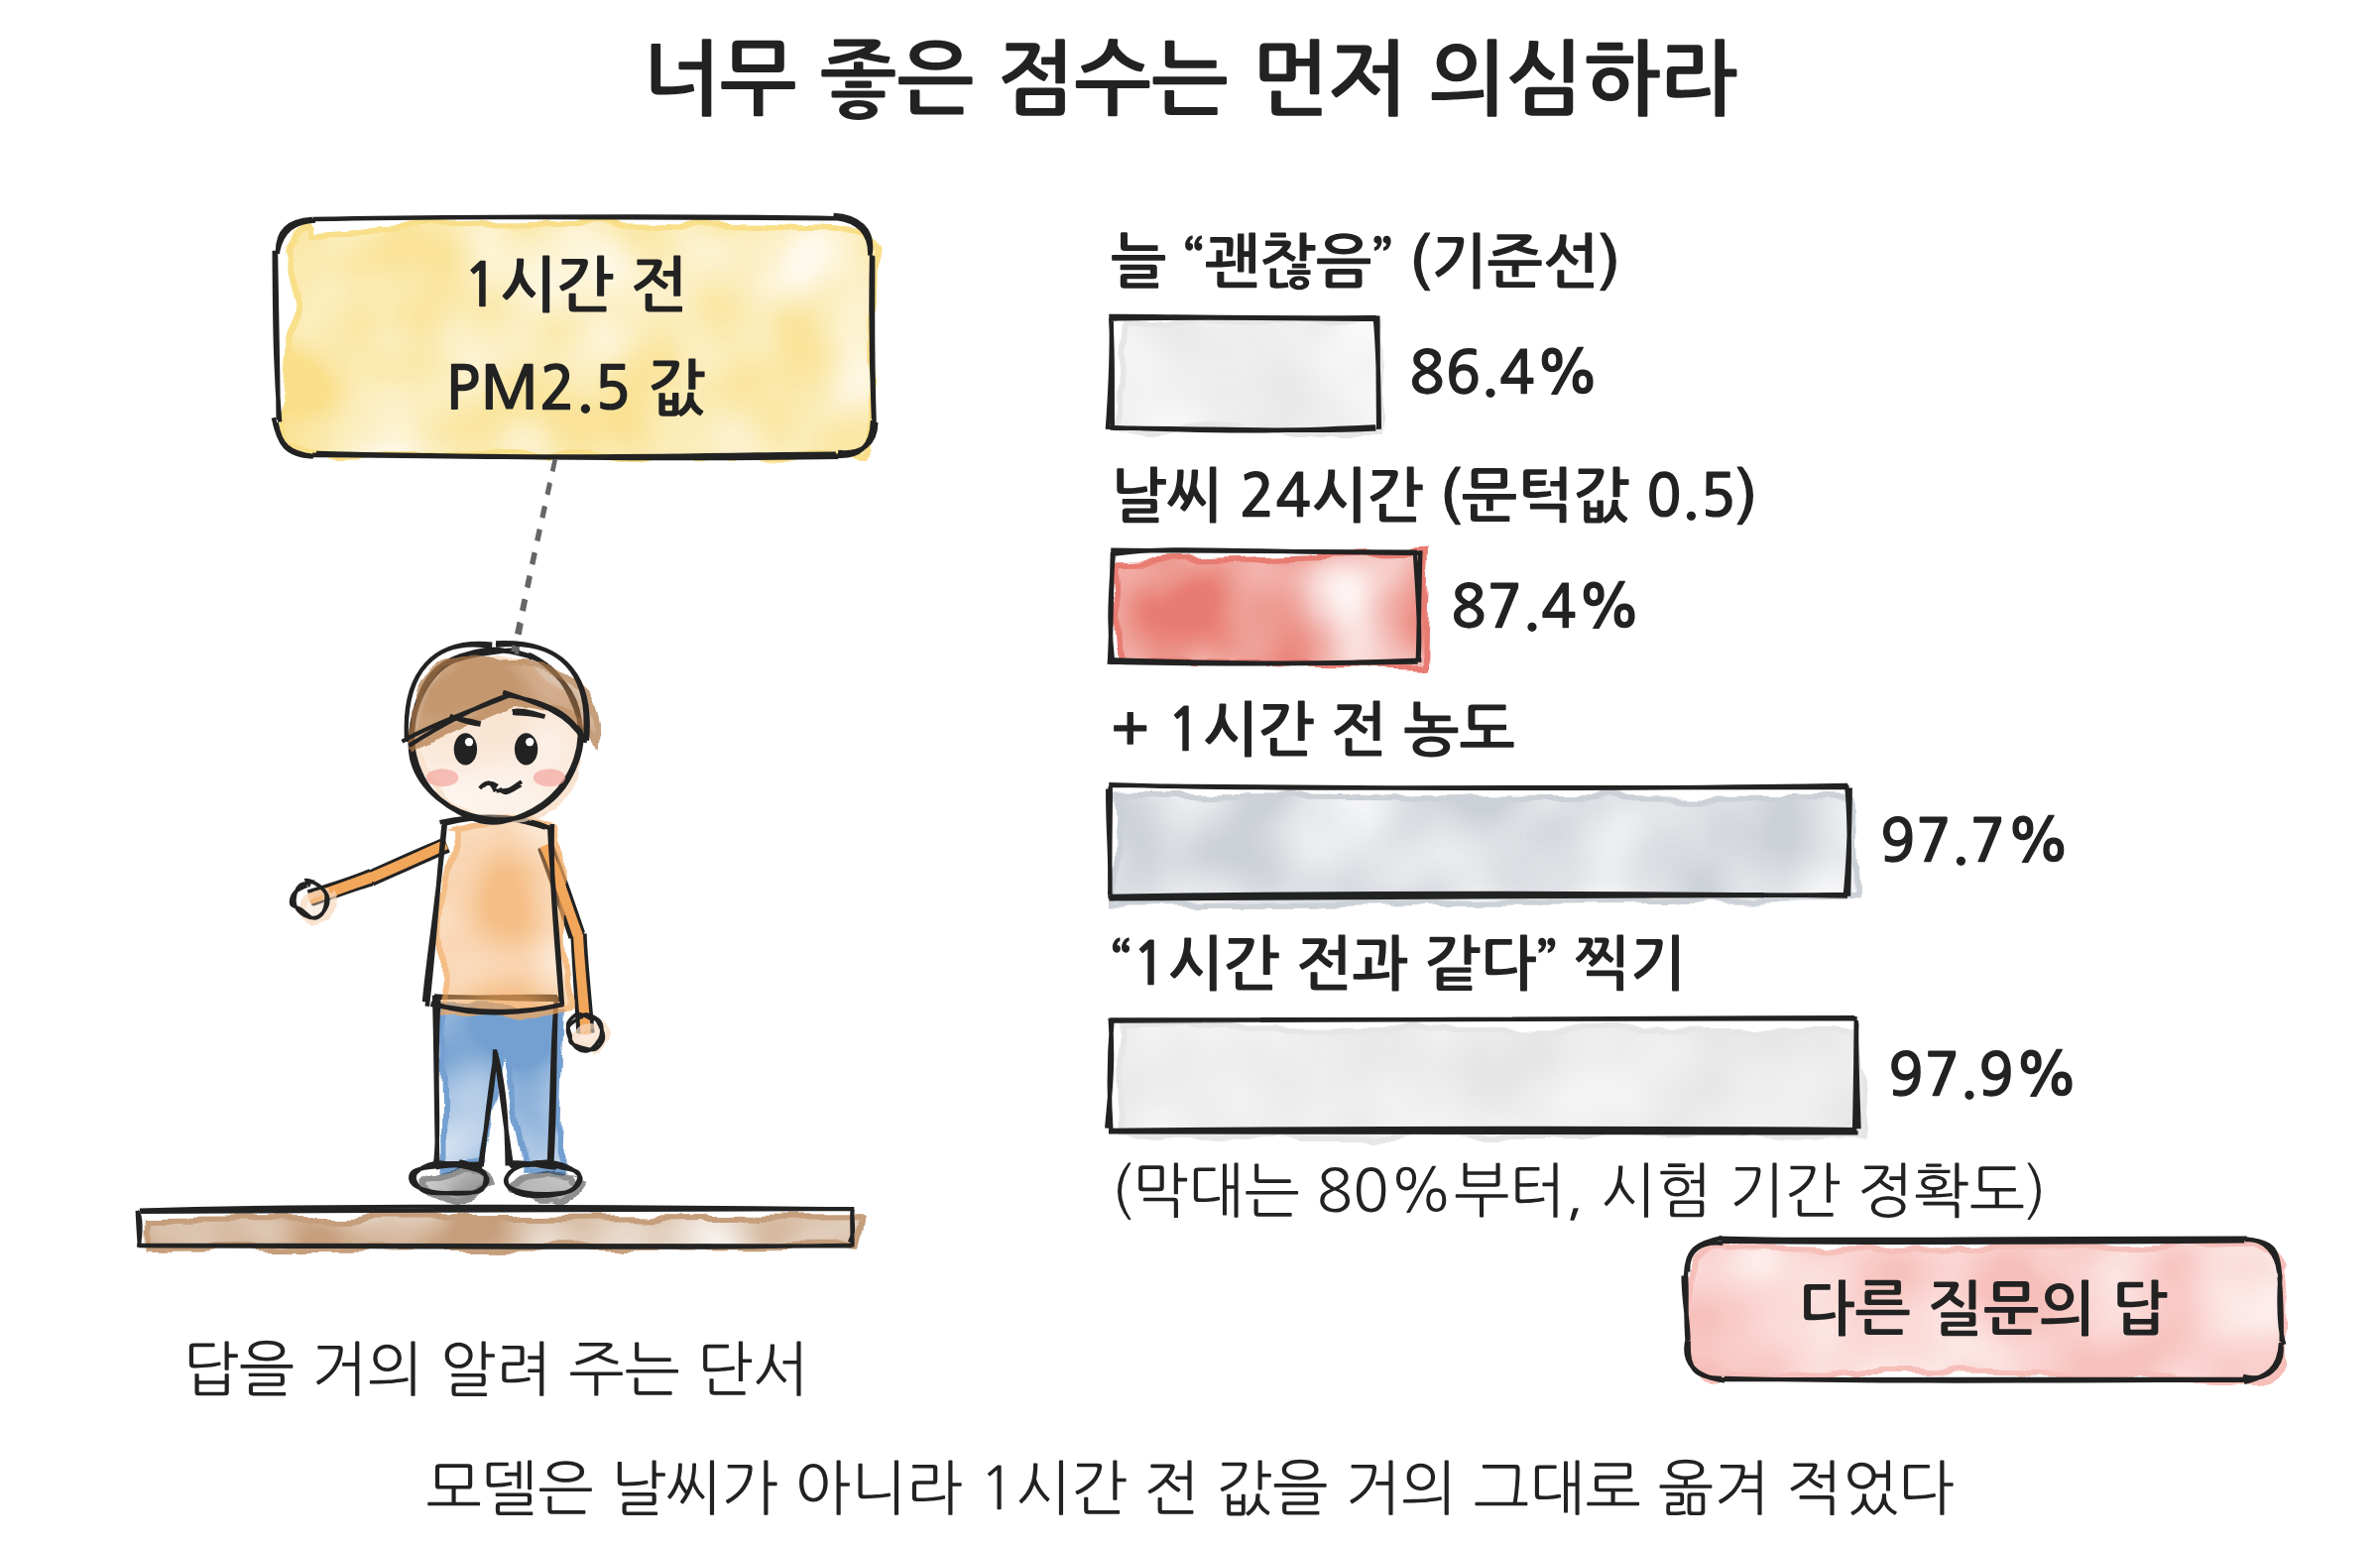

In [ ]:
cols = X_COLS + ["1시간전"]
lag = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lag.fit(past[cols], past["나쁨"])
print("1시간 전 농도를 넣으면 정확도:", round(lag.score(future[cols], yt), 3))
same = (future["1시간전"] > 35).astype(int)         # "1시간 전과 같다"고 찍기
print("'1시간 전과 같다'고 찍으면:", round(accuracy_score(yt, same), 3))

97.7%는 놀라운 점수처럼 보이지만, 새로 만든 기준선 "1시간 전과 같다"(97.9%)를 넘지 못합니다. 지금 농도를 아는 사람에게 "지금 나쁨"이라고 알려 주는 셈이라 알림 앱에는 쓸모가 없습니다. 좋은 점수가 나오면 먼저 **더 센 기준선**을 만들어 견줍니다.

**5단계: 한계 쓰기.** 이 모델이 아직 모르는 것을 [표 9-4]처럼 세 가지 이상 쓰시오. 바람 방향, 25곳 평균과 우리 동네의 차이, 예보 날씨를 써야 한다는 점을 생각해 보십시오.

**제출물.** 그림 2장, 성적표 1개(기준선, 모델, 문턱값별 손해), 결론 5문장 이내.

**[표 9-5] 미니 프로젝트 채점 기준**

| 항목(비중) | 상 | 중 | 하 |
|---|---|---|---|
| 데이터 점검(20%) | 빈칸의 뜻, 24시 표기, 등급 기준을 밝힘 | 빈칸만 처리함 | 점검 없음 |
| 기준선 비교(20%) | 시간 순서로 나누고 기준선과 견줌 | 무작위로 나눔 | 기준선 없음 |
| 기법 적용(30%) | 검증 기간으로 문턱값을 고르고 손해를 계산함 | 문턱값을 0.5로만 씀 | 코드가 돌지 않음 |
| 해석과 한계(30%) | 97.7%를 쓰면 안 되는 까닭과 한계 셋 이상 | 한계 한두 가지 | 숫자만 나열 |

**교수용 정답 예시.** 시험 기간 기준선 86.4%, 문턱값 0.5의 로지스틱 회귀 87.4%(재현율 14.5%). 검증 기간 손해는 문턱값 0.3에서 1,963으로 가장 작고(알림 없음 2,175), 시험 기간에는 재현율 38.3%, 손해 3,670(알림 없음 4,746, 문턱값 0.5는 4,176)입니다. 1시간 전 농도를 넣은 97.7%는 "1시간 전과 같다"(97.9%)를 넘지 못합니다.

## 연습문제 9-6 정답 코드

### [연습문제 9-6] 정확도가 높은 모델이 더 좋은가

헛경보가 놓침보다 열 배 나쁘다고 할 때, 문턱값 0.5에서 숫자 개수 모델과 단어 로지스틱 회귀의 손해(헛경보 × 10 + 놓침)를 구하고 견주시오. 정확도와 견주어 결과를 설명하시오.

**<정답>** 아래 코드로 셉니다([실습 예제 9-6]·[9-9]의 변수를 씀).

In [ ]:
th = 0.5
for name, pr in [("숫자 개수 하나", one.predict_proba(test[["숫자"]])[:, 1]),
                 ("로지스틱 회귀(단어)", prob)]:
    tn, fp, fn, tp = confusion_matrix(y, (pr >= th).astype(int)).ravel()
    print(f"{name}: 헛경보 {fp}  놓침 {fn}  손해 {10 * fp + fn}")

숫자 개수 하나: 헛경보 2  놓침 31  손해 51
로지스틱 회귀(단어): 헛경보 4  놓침 26  손해 66


정확도는 단어 모델(97.7%)이 숫자 개수 모델(97.4%)보다 높습니다. 그런데 헛경보를 열 배로 치면 숫자 개수 모델의 손해(51)가 단어 모델(66)보다 작습니다. 숫자 개수 모델은 스팸을 더 많이 놓치지만, 정상 문자를 스팸함에 넣는 일이 2통뿐이기 때문입니다. 어느 모델이 더 좋은지는 정확도가 아니라, 틀림의 값을 정한 뒤에야 답할 수 있습니다.